# 5 · Wheel-movement shapes in the proficient (BWM) cohort — global fits

Two fits of the same movements, as separate self-contained parts (run top to bottom; Part B re-does its own setup):
- **Part A · normalised**: each movement divided by its peak (shape only). Saved as `model_normalised.pkl`.
- **Part B · absolute** (was `5b_proficient_shapes_fit_absolute`): no peak normalisation. Saved as `model_absolute.pkl`; this is the version moved into `paper-individuality/segmentation/wheel_movement_clusters.py`.

## Part A · normalised velocity

Same method as `archive/4_movement_shapes`, fitted on the proficient LDA cohort. **Nothing is labelled or saved**: this notebook is for looking at the states before the data are labelled.

- Cohort: proficient syllable sessions, minus the QC sheet's 'filtered out', mice with ≥ 3 sessions (`proficient_movements.cohort()`, as `4_mice.functions.filter_sequences`).
- Velocity: the 60 Hz `avg_wheel_vel` of the BWM design matrices. Movements: IBL `wheelMoves`, padded by 50 ms.
- Each movement: signed (wheel coordinates), divided by its peak speed, linearly time-normalised to 200 bins. PCA (95 % variance, as the paw states' `CUTOFF`) + log duration → Gaussian mixture, K = 20.
- **Amplitude is not a feature**: every shape is divided by its peak speed, so two movements with the same shape and length but different vigor look identical to the clustering. Vigor (peak speed) is read out afterwards and used for the colour code.
- Clusters are then described by three heuristics -- **side** (which stimulus side the movement reports), **vigor** (peak speed), **jitter** (direction reversals) -- and coloured by the paper's state-palette rule (`paper_style.state_palette`: lightness = vigor rank, hue = side, chroma = how one-sided).
- **Sampling**: the same number of movements from every mouse (`N_PER_MOUSE`), split equally across its sessions, so no mouse or session dominates the fit.

In [1]:
import os
os.environ['OMP_NUM_THREADS'] = '1'
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from joblib import Parallel, delayed
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.metrics import normalized_mutual_info_score as nmi, adjusted_rand_score as ari
import proficient_movements as pm, primitives as pr
import sys; sys.path.insert(0, str(pm.PI))
import paper_style as ps

N_PER_MOUSE, K, VAR = 2000, 20, 0.95
NORMALISE = True      # True: each shape / its peak speed (amplitude-free); False: absolute velocity (rad/s)
SPLIT_BY_SIDE = not NORMALISE   # absolute velocity needs the side as a hard split (see the fit cell)
SPLIT, KG = 0.5, (7, 6, 7)      # |travel balance| > SPLIT = one-sided; clusters for - side / balanced / + side
VIGOR_CUTS = (1.0, 2.75)     # rad/s, median peak speed of a cluster: low | mid | high
coh = pm.cohort()
print(len(coh), 'sessions,', coh.mouse.nunique(), 'mice')

def one_session(mouse, eid):
    t, v, iv, tr = pm.load_session(eid, mouse)
    S, info = pm.shapes(t, v, iv, normalise=NORMALISE)
    info['mouse'], info['eid'] = mouse, eid
    ep = [pr.epoch_of(o, tr) for o in info.onset]
    info['epoch'] = [a for a, _ in ep]
    info['trial'] = [b for _, b in ep]
    info['stim_side'] = np.where(tr.contrastRight.notna().values, 'right', 'left')[np.maximum(info.trial, 0)]
    info['correct'] = (tr.feedbackType.values == 1)[np.maximum(info.trial, 0)]
    return S, info

out = Parallel(n_jobs=12)(delayed(one_session)(m, e) for m, e in zip(coh.mouse, coh.eid))
ALL_S = {e: s for (s, i), e in zip(out, coh.eid)}
ALL_I = {e: i for (s, i), e in zip(out, coh.eid)}
n_mv = pd.Series({e: len(i) for e, i in ALL_I.items()})
print(f'{n_mv.sum()} movements; per session median {n_mv.median():.0f} (range {n_mv.min()}-{n_mv.max()})')

269 sessions, 58 mice


391651 movements; per session median 1415 (range 626-3060)


### Representative sample: N_PER_MOUSE movements per mouse, equal across its sessions

In [2]:
rng = np.random.default_rng(0)
Ss, Is = [], []
for mouse, g in coh.groupby('mouse'):
    per = int(np.ceil(N_PER_MOUSE / len(g)))
    for e in g.eid:
        n = len(ALL_I[e]); idx = rng.choice(n, min(per, n), replace=False)
        Ss.append(ALL_S[e][idx]); Is.append(ALL_I[e].iloc[idx])
S = np.concatenate(Ss); info = pd.concat(Is, ignore_index=True)
print(len(info), 'movements in the fit;', info.groupby('mouse').size().describe()[['min', '50%', 'max']].to_dict())

116056 movements in the fit; {'min': 2000.0, '50%': 2000.5, 'max': 2007.0}


### Check: is 60 Hz enough? Same movements from 200 Hz wheel rebuilt from IBL data (2 sessions)

In [3]:
from one.api import ONE
from brainbox.behavior.wheel import interpolate_position, velocity_filtered
one = ONE(mode='remote')
chk = []
for e in coh.eid.iloc[[0, len(coh) // 2]]:
    w = one.load_object(e, 'wheel', collection='alf')
    pos, t1k = interpolate_position(w['timestamps'], w['position'], freq=1000)
    vel, _ = velocity_filtered(pos, fs=1000)
    t200, v200 = t1k[::5], vel[::5]
    m = coh.set_index('eid').mouse[e]
    t60, v60, iv, _ = pm.load_session(e, m)
    S60, i60 = pm.shapes(t60, v60, iv, normalise=NORMALISE)
    S200, i200 = pm.shapes(t200, v200, iv, normalise=NORMALISE)
    both = i60.reset_index().merge(i200.reset_index(), on='movement', suffixes=('_60', '_200'))
    r = [np.corrcoef(S60[a], S200[b])[0, 1] for a, b in zip(both.index_60, both.index_200)]
    chk.append(dict(eid=e, movements=len(both), median_r=np.median(r), r_10th_pct=np.percentile(r, 10),
                    peak_ratio=np.median(both.peak_60 / both.peak_200)))
    CHK = (S60[both.index_60], S200[both.index_200], both)
pd.DataFrame(chk).round(3)

/home/ines/miniconda3/envs/iblenv/lib/python3.10/site-packages/one/util.py:436: ALFWarning: Multiple revisions: "", "2024-05-06"
  warnings.warn(f'Multiple revisions: {rev_list}', alferr.ALFWarning)


,eid,movements,median_r,r_10th_pct,peak_ratio
0,034e726f-b35f-41e0-8d6c-a22cc32391fb,1104,0.996,0.985,0.997
1,1d4a7bd6-296a-48b9-b20e-bd0ac80750a5,1431,0.997,0.985,0.997


### PCA + clustering

11 PCs kept


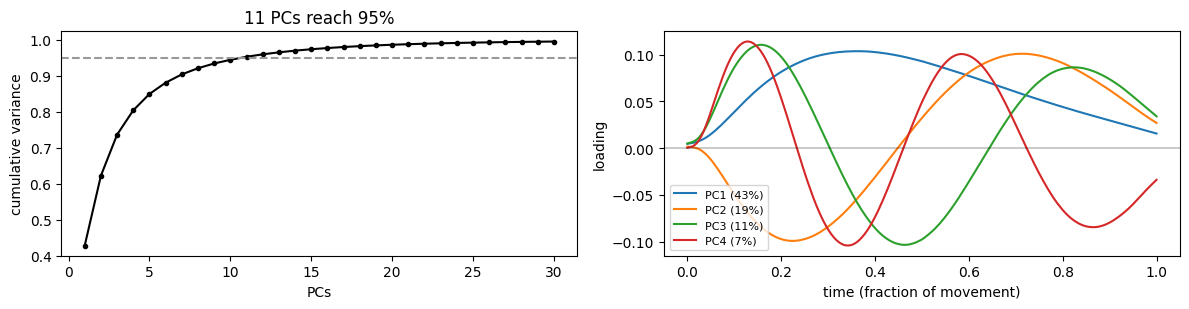

In [4]:
pca = PCA().fit(S)
n_pc = int(np.searchsorted(np.cumsum(pca.explained_variance_ratio_), VAR) + 1)
def features(S_, info_):
    F = np.column_stack([pca.transform(S_)[:, :n_pc], np.log10(info_.duration)])
    return (F - MU) / SD
F0 = np.column_stack([pca.transform(S)[:, :n_pc], np.log10(info.duration)])
MU, SD = F0.mean(0), F0.std(0)
F = (F0 - MU) / SD
def side_of(S_):
    pos = np.clip(S_, 0, None).sum(1); neg = np.clip(-S_, 0, None).sum(1)
    si = (pos - neg) / (pos + neg)                 # wheel coordinates: + / - travel balance
    return np.where(si > SPLIT, 2, np.where(si < -SPLIT, 0, 1))
if SPLIT_BY_SIDE:
    # absolute velocity: a single mixture builds nested, centred clusters of increasing speed that hold
    # both directions, so the wheel side is a hard split first: -side / balanced / +side, then a mixture each
    grp = side_of(S)
    GM = {g: GaussianMixture(KG[g], covariance_type='full', n_init=5, random_state=0).fit(F[grp == g]) for g in range(3)}
    OFF = np.r_[0, np.cumsum(KG)[:-1]]
    def predict(S_, info_):
        F_, g_ = features(S_, info_), side_of(S_)
        out = np.empty(len(S_), int)
        for g in range(3):
            if (g_ == g).any(): out[g_ == g] = GM[g].predict(F_[g_ == g]) + OFF[g]
        return out
else:
    gmm = GaussianMixture(K, covariance_type='full', n_init=5, random_state=0).fit(F)
    def predict(S_, info_):
        return gmm.predict(features(S_, info_))
lab = predict(S, info)
info['raw'] = lab
x = np.linspace(0, 1, pm.NT)

fig, axs = plt.subplots(1, 2, figsize=(12, 3.2))
axs[0].plot(np.arange(1, 31), np.cumsum(pca.explained_variance_ratio_[:30]), 'o-', c='k', ms=3)
axs[0].axhline(VAR, c='0.6', ls='--'); axs[0].set(xlabel='PCs', ylabel='cumulative variance', title=f'{n_pc} PCs reach {VAR:.0%}')
for i in range(4):
    axs[1].plot(x, pca.components_[i], label=f'PC{i + 1} ({pca.explained_variance_ratio_[i]:.0%})')
axs[1].axhline(0, c='k', lw=.3); axs[1].set(xlabel='time (fraction of movement)', ylabel='loading'); axs[1].legend(fontsize=8)
plt.tight_layout()
print(f'{n_pc} PCs kept')

### Describing the clusters: side, vigor, jitter

Per movement (from its signed, peak-normalised shape and its peak speed), then summarised per cluster:
- **side index** = (∫v⁺ − ∫v⁻) / (∫v⁺ + ∫v⁻), the balance of wheel travel in the two directions, then mapped to the stimulus side it reports. The mapping is measured, not assumed: on correct response-epoch movements, which wheel sign goes with right-side stimuli. +1 = all travel reports a right stimulus, −1 = left, 0 = balanced back-and-forth.
- **vigor** = median peak speed (rad/s).
- **jitter** = direction reversals per movement, counted where |v| > 10 % of the peak (so encoder noise around zero is ignored).

Heuristic labels: side = right / left if |median side index| > 0.5, else 'both'; vigor = low / mid / high by the cluster's median peak speed (< 1, 1–2.75, > 2.75 rad/s: fixed cuts, so the label means the same whatever the side); jitter = smooth (≤ 1 reversal), corrective (2–3), jittery (≥ 4).

In [5]:
pos = np.clip(S, 0, None).sum(1); neg = np.clip(-S, 0, None).sum(1)
si_wheel = (pos - neg) / (pos + neg)
def reversals(a, thr=.1):
    sg = np.sign(np.where(np.abs(a) > thr, a, 0))
    sg = sg[sg != 0]
    return int((np.diff(sg) != 0).sum())
info['reversals'] = [reversals(a, .1 * np.abs(a).max()) for a in S]
# which wheel sign reports a right stimulus? correct response-epoch movements
c = info[(info.epoch == 'response') & info.correct & (info.trial >= 0)]
p_pos_right = (si_wheel[c.index][c.stim_side == 'right'] > 0).mean()
p_pos_left = (si_wheel[c.index][c.stim_side == 'left'] > 0).mean()
SIGN_RIGHT = 1 if p_pos_right > p_pos_left else -1
print(f'P(+ wheel | right stim, correct) = {p_pos_right:.2f},  P(+ wheel | left stim, correct) = {p_pos_left:.2f}'
      f'  ->  + wheel reports {"right" if SIGN_RIGHT > 0 else "left"}')
info['side_index'] = si_wheel * SIGN_RIGHT          # + = reports right stimulus

desc = info.groupby('raw').agg(fraction=('raw', lambda c: len(c) / len(info)), side_index=('side_index', 'median'),
                               peak_rad_s=('peak', 'median'), reversals=('reversals', 'median'),
                               duration_s=('duration', 'median'),
                               response=('epoch', lambda e: (e == 'response').mean()),
                               post_feedback=('epoch', lambda e: (e == 'post-feedback').mean()))
desc['side'] = np.where(desc.side_index > .5, 'right', np.where(desc.side_index < -.5, 'left', 'both'))
desc['vigor'] = pd.cut(desc.peak_rad_s, [0, VIGOR_CUTS[0], VIGOR_CUTS[1], np.inf], labels=['low', 'mid', 'high']).astype(str)
desc['jitter'] = pd.cut(desc.reversals, [-1, 1, 3, 99], labels=['smooth', 'corrective', 'jittery']).astype(str)
# display order: left -> both -> right, and within a side from low to high vigor
side_rank = desc.side.map({'left': 0, 'both': 1, 'right': 2})
desc = desc.assign(_s=side_rank).sort_values(['_s', 'peak_rad_s']).drop(columns='_s')
desc['cls'] = np.arange(K)
REL = dict(zip(desc.index, desc.cls))
info['cls'] = info.raw.map(REL)
desc = desc.set_index('cls')
desc['label'] = desc.side + ' ' + desc.vigor + ' ' + desc.jitter
# colours: the paper's rule. gap > 0 -> hues[0]. Left = violet (310), right = amber (90), as the paw states.
COL = ps.state_palette(np.log(desc.peak_rad_s.values), gap=-desc.side_index.values, hues=(310, 90))
HATCH = {'smooth': '', 'corrective': '..', 'jittery': '////'}
print('NMI(cluster, mouse) =', round(nmi(info.mouse, info.cls), 3))
desc.round(2)

P(+ wheel | right stim, correct) = 0.82,  P(+ wheel | left stim, correct) = 0.18  ->  + wheel reports right
NMI(cluster, mouse) = 0.048


,fraction,side_index,peak_rad_s,reversals,duration_s,response,post_feedback,side,vigor,jitter,label
cls,,,,,,,,,,,
0,0.03,-1.00,0.31,0.0,0.10,0.18,0.64,left,low,smooth,left low smooth
1,0.04,-0.65,0.42,1.0,0.31,0.19,0.65,left,low,smooth,left low smooth
2,0.03,-0.93,2.16,1.0,0.37,0.43,0.34,left,mid,smooth,left mid smooth
3,0.04,-0.92,3.09,1.0,0.65,0.69,0.14,left,high,smooth,left high smooth
4,0.04,-0.66,3.20,2.0,0.94,0.79,0.10,left,high,corrective,left high corrective
5,0.05,-0.25,0.75,1.0,0.26,0.21,0.59,both,low,smooth,both low smooth
6,0.13,0.01,1.81,3.0,0.84,0.36,0.41,both,mid,corrective,both mid corrective
7,0.09,-0.16,2.16,2.0,0.59,0.34,0.36,both,mid,corrective,both mid corrective
8,0.11,0.02,3.07,5.0,1.35,0.58,0.19,both,high,jittery,both high jittery


#### Is the clustering sensitive to amplitude?

clusters explain 62% of the variance in log peak speed (through shape and duration, not amplitude itself)


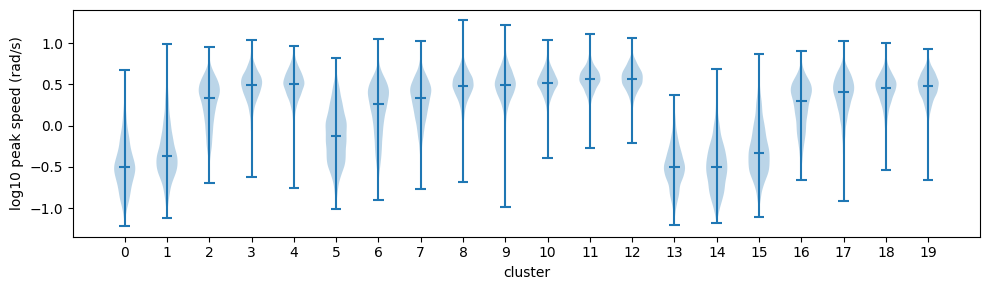

In [6]:
# shapes are peak-normalised, so vigor is not a feature; how much of the peak-speed variance do clusters capture anyway?
lp = np.log10(info.peak)
eta2 = 1 - info.assign(lp=lp).groupby('cls').lp.transform(lambda z: z - z.mean()).pow(2).sum() / ((lp - lp.mean()) ** 2).sum()
print(f'clusters explain {eta2:.0%} of the variance in log peak speed (through shape and duration, not amplitude itself)')
fig, ax = plt.subplots(figsize=(10, 3))
ax.violinplot([lp[info.cls == c] for c in range(K)], positions=range(K), showmedians=True)
ax.set(xticks=range(K), xlabel='cluster', ylabel='log10 peak speed (rad/s)'); plt.tight_layout()

#### Legend: the colour code

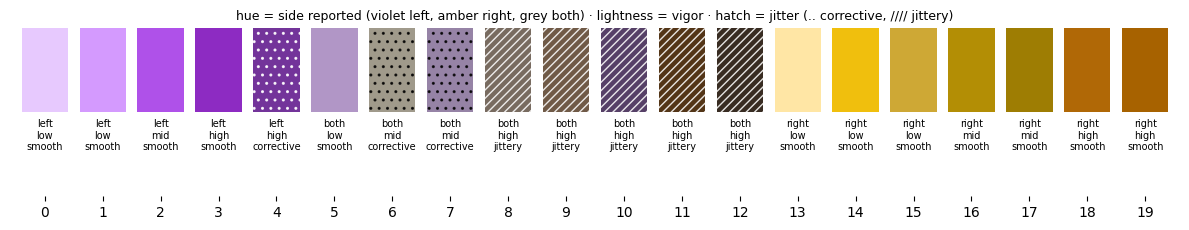

In [7]:
fig, ax = plt.subplots(figsize=(12, 2.4))
for c in range(K):
    ax.bar(c, 1, color=COL[c], hatch=HATCH[desc.jitter[c]], edgecolor=ps.hatch_ink(COL[c]), lw=0)
    ax.text(c, -.08, desc.label[c].replace(' ', '\n'), ha='center', va='top', fontsize=7)
ax.set(xticks=range(K), xlim=(-.6, K - .4), ylim=(-1.0, 1), yticks=[])
ax.set_title('hue = side reported (violet left, amber right, grey both) · lightness = vigor · hatch = jitter (.. corrective, //// jittery)', fontsize=9)
for sp in ax.spines.values(): sp.set_visible(False)
plt.tight_layout()

### Save the fitted model (no labels)

The PCA, standardisation, mixture(s), display order, labels and colours, so other notebooks can label any session with `proficient_movements.predict` / `session_labels`.

In [8]:
import pickle
MODEL = dict(variant='normalised' if NORMALISE else 'absolute', normalise=NORMALISE, pca=pca, n_pc=n_pc, MU=MU, SD=SD,
             split_by_side=SPLIT_BY_SIDE, SPLIT=SPLIT, REL=REL, desc=desc, COL=COL, HATCH=HATCH, K=K)
if SPLIT_BY_SIDE:
    MODEL.update(GM=GM, OFF=OFF)
else:
    MODEL['gmm'] = gmm
with open(pm.model_path(MODEL['variant']), 'wb') as f:
    pickle.dump(MODEL, f)
print('saved', pm.model_path(MODEL['variant']))

saved /home/ines/repositories/representation_learning_variability/paper-individuality/data/wheel_movements_proficient/model_normalised.pkl


#### 60 vs 200 Hz: do the same movements get the same cluster?

In [9]:
S60, S200, both = CHK
l60 = predict(S60, both.rename(columns={'duration_60': 'duration'}))
l200 = predict(S200, both.rename(columns={'duration_200': 'duration'}))
print(f'{len(both)} movements: same cluster {np.mean(l60 == l200):.0%}, ARI {ari(l60, l200):.2f}')

1431 movements: same cluster 92%, ARI 0.86


#### Each cluster: 60 random members (thin) and median (thick); x = fraction of the movement, + = one wheel direction

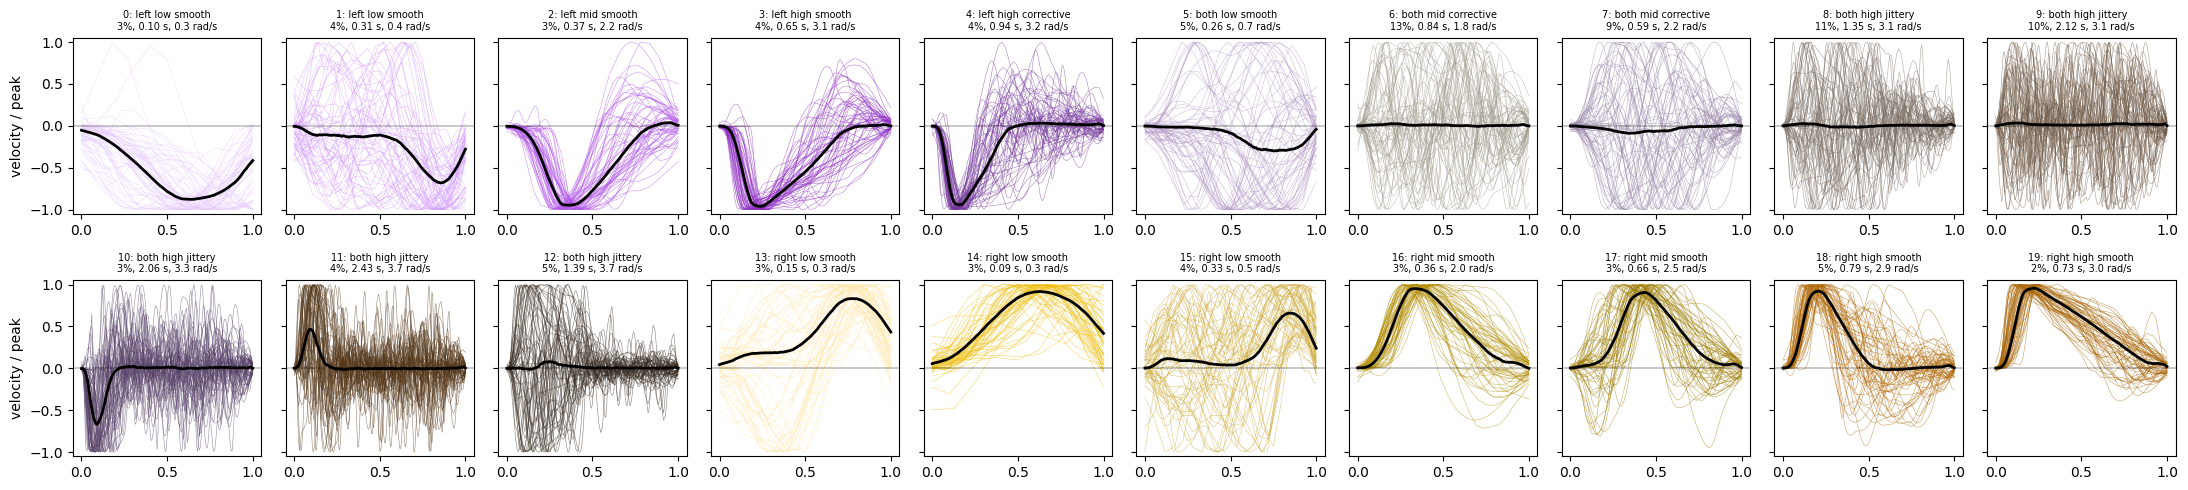

In [10]:
YL = np.percentile(np.abs(S), 99.5)
fig, axs = plt.subplots(2, K // 2, figsize=(2.2 * K / 2, 5), sharey=True)
for c, ax in enumerate(axs.flat):
    a = S[info.cls == c]
    ax.plot(x, a[rng.choice(len(a), min(60, len(a)), replace=False)].T, c=COL[c], lw=.4, alpha=.6)
    ax.plot(x, np.median(a, 0), c='k', lw=2); ax.axhline(0, c='k', lw=.3)
    ax.set_ylim(-1.05, 1.05) if NORMALISE else ax.set_ylim(-YL, YL)
    ax.set_title(f'{c}: {desc.label[c]}\n{len(a) / len(S):.0%}, {desc.duration_s[c]:.2f} s, {desc.peak_rad_s[c]:.1f} rad/s', fontsize=7)
for ax in axs[:, 0]: ax.set_ylabel('velocity / peak' if NORMALISE else 'velocity (rad/s)')
plt.tight_layout()

#### Each cluster in real time: random members from any mouse, rad/s, x = seconds from onset

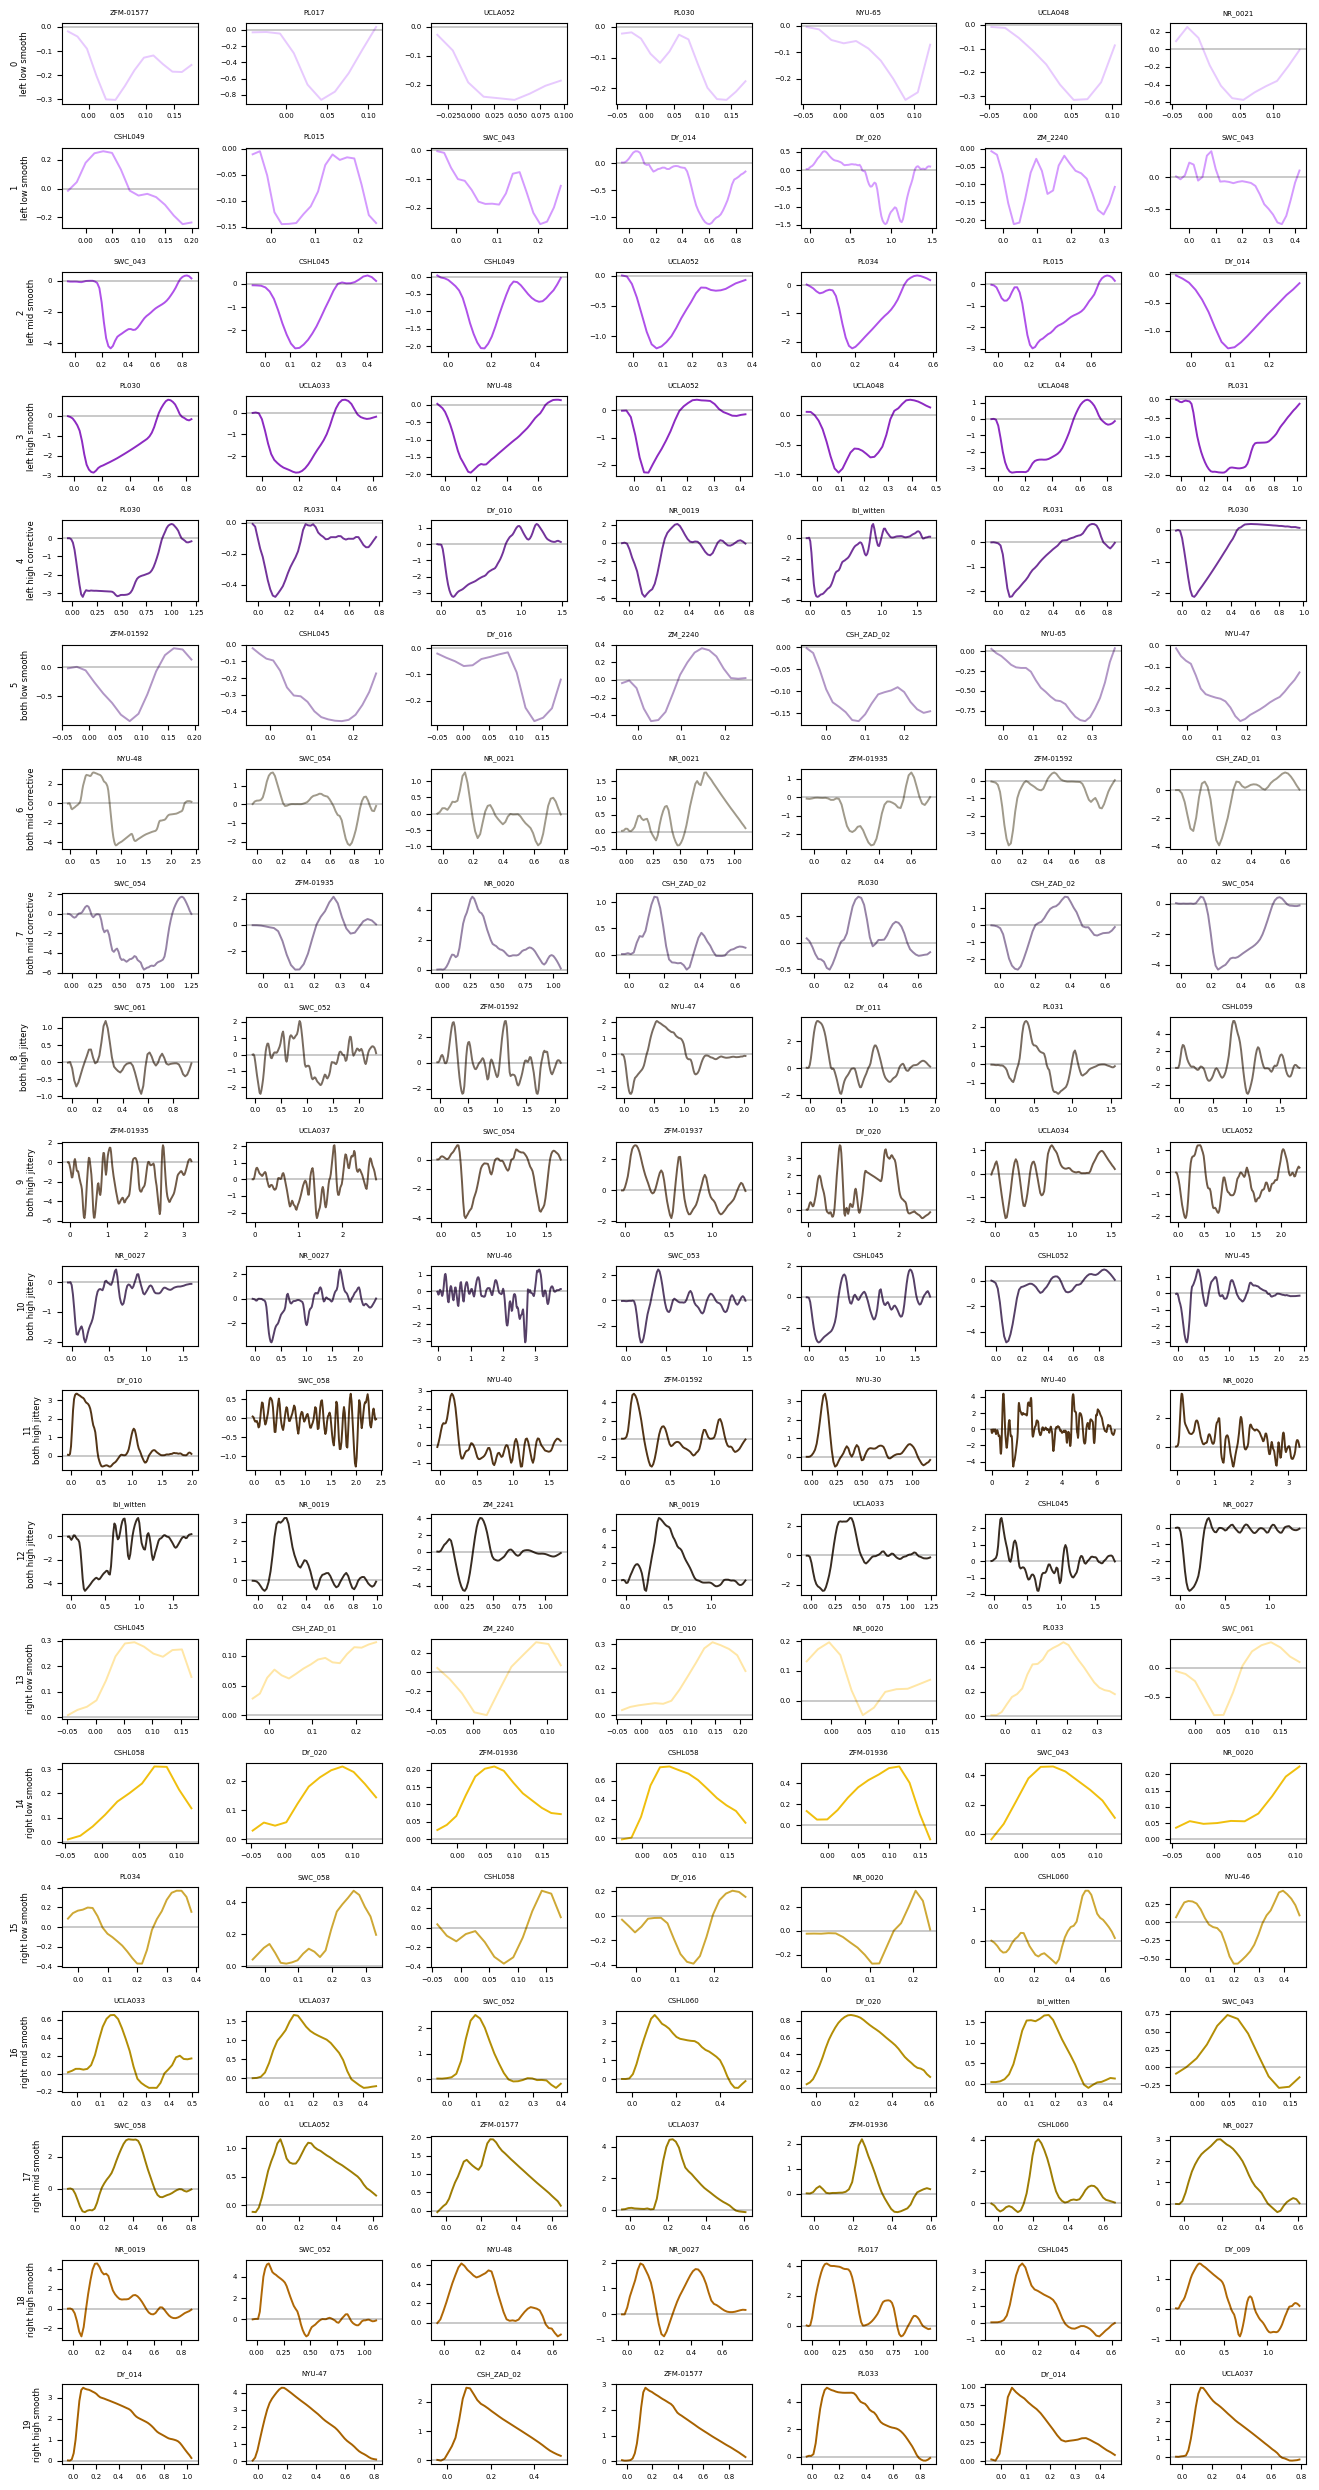

In [11]:
N_EX = 7
DMC = {}
def vel(e):
    if e not in DMC:
        m = coh.set_index('eid').mouse[e]
        DMC[e] = pm.load_session(e, m)[:2]
    return DMC[e]
fig, axs = plt.subplots(K, N_EX, figsize=(1.9 * N_EX, 1.25 * K), squeeze=False)
for c in range(K):
    for j, i in enumerate(rng.choice(info.index[info.cls == c], N_EX, replace=False)):
        q = info.loc[i]; t, v = vel(q.eid); ax = axs[c, j]
        i0, i1 = np.searchsorted(t, [q.onset - pm.PAD_S, q.offset + pm.PAD_S])
        ax.plot(t[i0:i1] - q.onset, v[i0:i1], c=COL[c], lw=1.4); ax.axhline(0, c='k', lw=.3); ax.tick_params(labelsize=5)
        ax.set_title(q.mouse[:10], fontsize=5)
    axs[c, 0].set_ylabel(f'{c}\n{desc.label[c]}', fontsize=6)
plt.tight_layout()

### Shared across mice? Cluster use per mouse (rows = mice, sorted by lab name)

clusters used by every mouse (> 0.5 % of its movements): 8 of 20


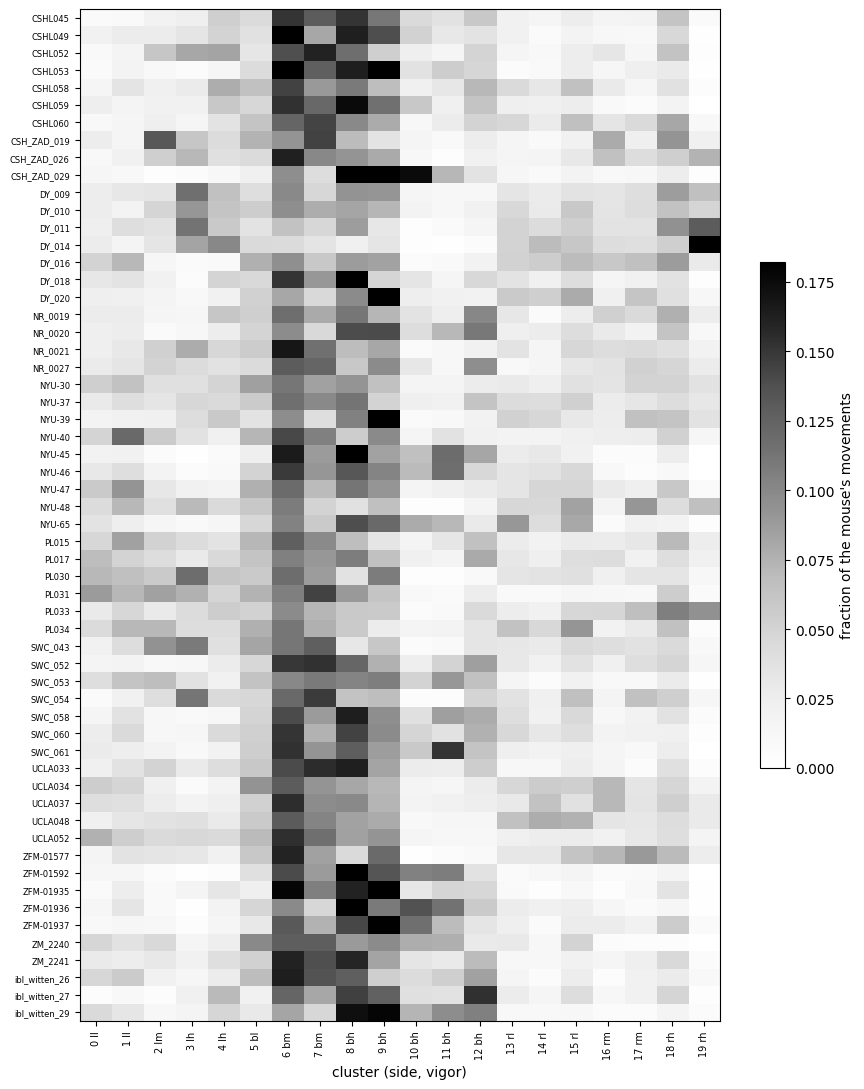

In [12]:
u = info.groupby('mouse').cls.value_counts(normalize=True).unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(9, 11))
im = ax.imshow(u.values, aspect='auto', cmap='Greys', vmax=np.percentile(u.values, 99))
ax.set_yticks(range(len(u)), u.index, fontsize=6); ax.set_xticks(range(K), [f'{c} {desc.side[c][0]}{desc.vigor[c][0]}' for c in range(K)], fontsize=7, rotation=90); ax.set_xlabel('cluster (side, vigor)')
plt.colorbar(im, ax=ax, label='fraction of the mouse\'s movements', shrink=.5); plt.tight_layout()
print('clusters used by every mouse (> 0.5 % of its movements):', int(((u > .005).all(0)).sum()), 'of', K)

#### The clusters in time (display only, nothing saved): 25 s from 4 sessions of different mice

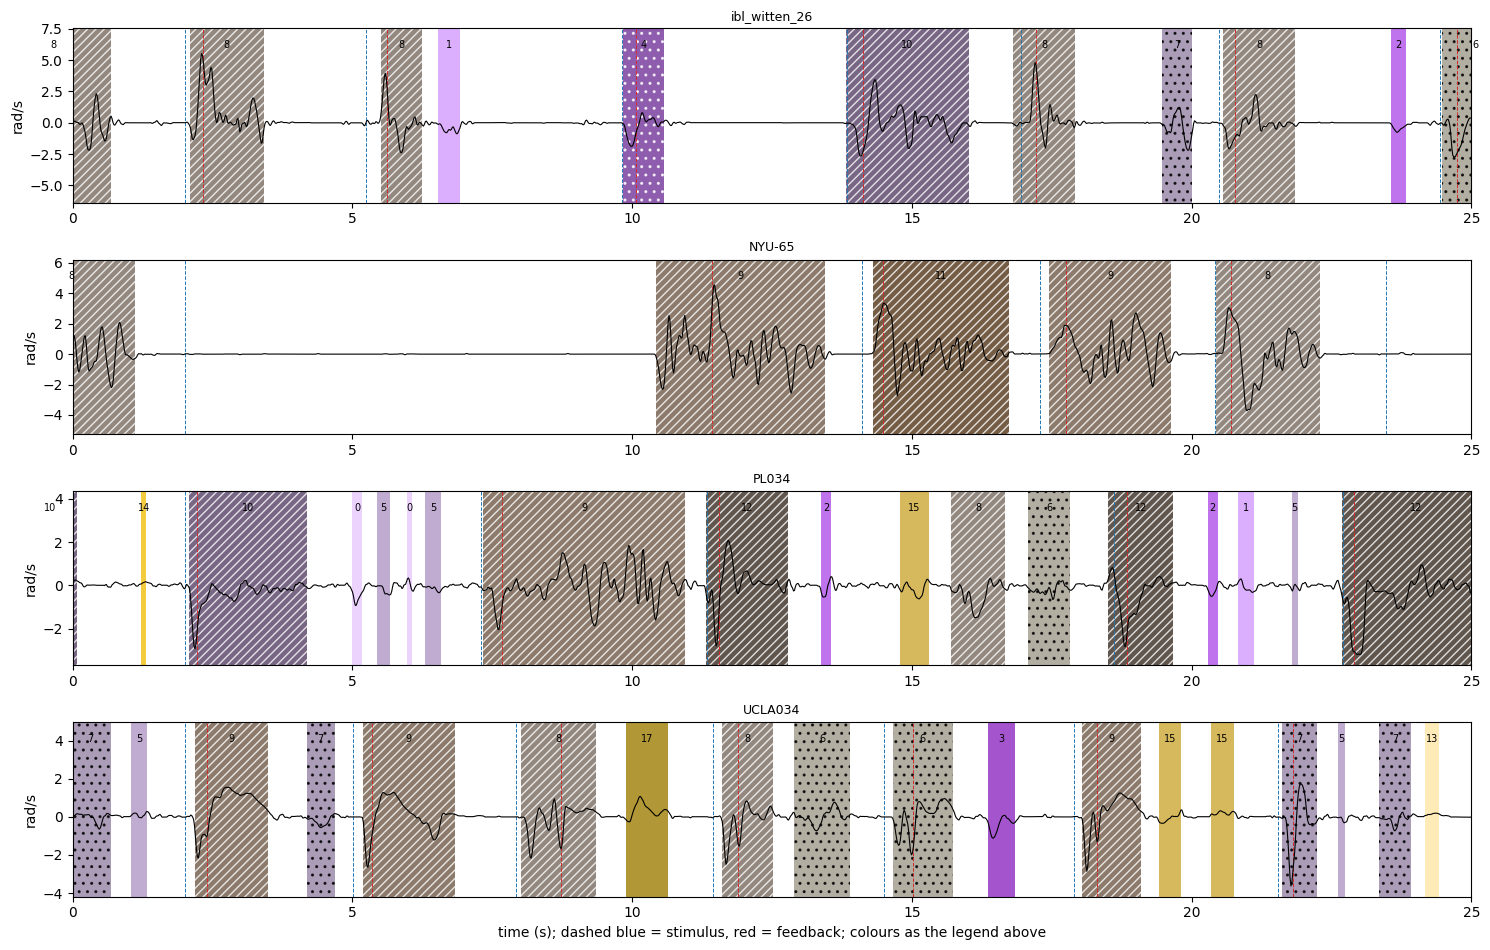

In [13]:
def timeline(e, ax, frac=.4, win=25):
    m = coh.set_index('eid').mouse[e]
    t, v, iv, tr = pm.load_session(e, m)
    Se, ie = ALL_S[e], ALL_I[e]
    le = pd.Series(predict(Se, ie)).map(REL).values
    stim = pr.stim_times(tr)
    t0 = stim.iloc[int(frac * len(tr))] - 2
    sel = (t > t0) & (t < t0 + win)
    ax.plot(t[sel] - t0, v[sel], c='k', lw=.8, zorder=3)
    top = np.nanmax(np.abs(v[sel])) * 1.05
    for (_, q), c in zip(ie.iterrows(), le):
        if q.offset > t0 and q.onset < t0 + win:
            ax.axvspan(q.onset - t0, q.offset - t0, facecolor=COL[c], hatch=HATCH[desc.jitter[c]], edgecolor=ps.hatch_ink(COL[c]), alpha=.8, lw=0)
            ax.text((q.onset + q.offset) / 2 - t0, top, str(c), ha='center', va='bottom', fontsize=7)
    for ev, col in [(stim.values, 'tab:blue'), (tr.feedback_times.values, 'tab:red')]:
        for x_ in ev:
            if 0 < x_ - t0 < win: ax.axvline(x_ - t0, c=col, ls='--', lw=.7)
    ax.set(xlim=(0, win), ylim=(-top * 1.1, top * 1.3), ylabel='rad/s'); ax.set_title(m, fontsize=9)

show = coh.groupby('mouse').eid.first().sample(4, random_state=2).values
fig, axs = plt.subplots(len(show), 1, figsize=(15, 2.4 * len(show)))
for ax, e in zip(axs, show):
    timeline(e, ax)
axs[-1].set_xlabel('time (s); dashed blue = stimulus, red = feedback; colours as the legend above')
plt.tight_layout()

### How short are movements, and do they survive the syllables' 10-bin trial warping?
    
    The syllable pipeline cuts each trial into its four epochs (pre-quiescence, quiescence, choice, ITI) and rescales each to 10 bins by taking the **mode** within each bin. A movement survives if it is the most common thing in at least one bin. Measured on 30 random cohort sessions with the current proficient states files, for the wheel digit on its own (a movement id per 60 Hz frame, -1 = still).

In [14]:
import os, sys
sys.path.insert(0, str(pm.PI / 'segmentation'))
from syllable_pipeline import rescale_sequence
SF = pm.PI / 'data' / 'states_files'
coh30 = pm.cohort().sample(30, random_state=0)
rows, ep = [], []
for _, r in coh30.iterrows():
    f = SF / f'8_states_file_{r.eid}_{r.mouse}'
    if not f.exists(): continue
    st = pd.read_parquet(f, columns=['Bin', 'trial_id', 'broader_label']).dropna(subset=['trial_id', 'broader_label'])
    iv = np.load(pm.CACHE / f'intervals_{r.eid}_{r.mouse}.npy')
    b = st.Bin.values
    mid = np.full(len(b), -1)
    for k, (on, off) in enumerate(iv):
        i0, i1 = np.searchsorted(b, [on, off]); mid[i0:i1] = k
    st['mid'] = mid
    seen, lost_epoch = set(), {}
    for (t, lab), g in st.groupby(['trial_id', 'broader_label'], sort=False):
        ep.append(dict(epoch=lab, n=len(g)))
        m = g.mid.values
        a = rescale_sequence(m, 10, 'mode')
        seen |= set(a[a >= 0])
        for k in set(m[m >= 0]): lost_epoch.setdefault(k, lab)
    for k, (on, off) in enumerate(iv):
        if on < b[0] or off > b[-1]: continue
        rows.append(dict(dur=off - on, survives=k in seen, epoch=lost_epoch.get(k)))
E = pd.DataFrame(ep); Mv = pd.DataFrame(rows)
E['bin_ms'] = E.n / 10 / 60 * 1000
print('movement duration percentiles 1/5/10/25/50 % (s):', np.percentile(Mv.dur, [1, 5, 10, 25, 50]).round(3))
print(f'overall {Mv.survives.mean():.0%} of movements own at least one bin')
Mv['duration'] = pd.cut(Mv.dur, [0, .05, .1, .2, .3, .5, 1, 2, 100])
display(E.groupby('epoch').bin_ms.describe(percentiles=[.1, .5, .9])[['10%', '50%', '90%']].round(0).rename(columns=lambda c: f'bin width ms, {c}'))
display(Mv.groupby('duration', observed=True).agg(movements=('dur', 'size'), survive=('survives', 'mean')).round(2))
display(pd.crosstab(Mv.epoch, Mv.survives, normalize='index').round(2).rename(columns={False: 'lost', True: 'survive'}))

movement duration percentiles 1/5/10/25/50 % (s): [0.064 0.134 0.222 0.458 0.785]
overall 88% of movements own at least one bin


,"bin width ms, 10%","bin width ms, 50%","bin width ms, 90%"
epoch,,,
Choice,23.0,38.0,302.0
ITI,155.0,157.0,158.0
Pre-quiescence,5.0,12.0,202.0
Quiescence,42.0,52.0,65.0


,movements,survive
duration,,
"(0.05, 0.1]",1172,0.24
"(0.1, 0.2]",2165,0.53
"(0.2, 0.3]",2039,0.66
"(0.3, 0.5]",5355,0.82
"(0.5, 1.0]",12740,0.94
"(1.0, 2.0]",10436,0.99
"(2.0, 100.0]",3932,1.00


survives,lost,survive
epoch,,
Choice,0.07,0.93
ITI,0.11,0.89
Pre-quiescence,0.06,0.94
Quiescence,0.04,0.96


### Mouse ICC of cluster occupancy

Every movement of every cohort session is labelled **in memory** (nothing saved). Per session: the fraction of its movements in each cluster, overall and within each trial epoch (by movement onset). ICC(1) per cluster: one-way random effects with mice as groups and sessions as repeats (unequal group sizes handled with the usual n0). ICC = share of the session-to-session variance in occupancy that is between mice. The table is written to `icc_<variant>.csv` in the movement cache, so the variants can be compared.

ONE mouse ICC per epoch for the whole occupancy profile (Hellinger = on sqrt(occupancy), less dominated by the big clusters):


,icc_occupancy,icc_hellinger
epoch,,
all,0.631,0.662
pre-stim,0.540,0.535
response,0.603,0.615
post-feedback,0.500,0.525


/tmp/ipykernel_216409/1665315986.py:43: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  summ_icc = ICC.groupby('epoch').apply(lambda d: pd.Series({'median ICC': d.icc.median(),


,median ICC,occupancy-weighted ICC,clusters ICC > 0.3
epoch,,,
all,0.567,0.595,20.0
pre-stim,0.513,0.518,19.0
response,0.516,0.557,19.0
post-feedback,0.530,0.492,18.0


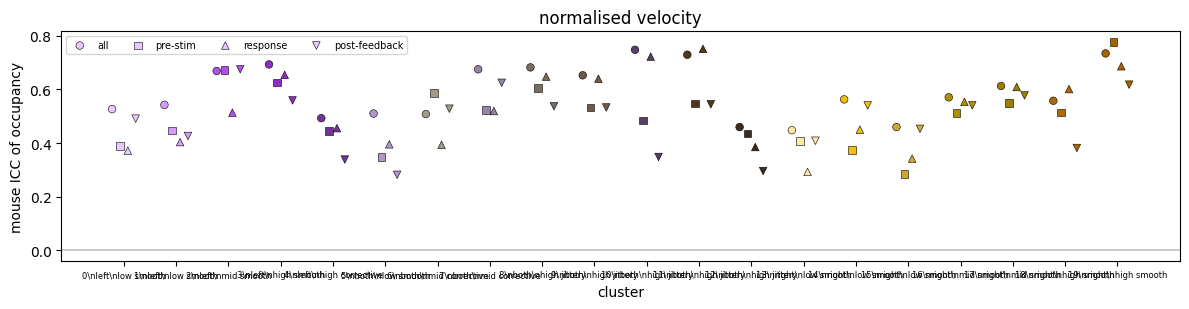

In [15]:
def icc1(df, value, group='mouse'):
    g = df.groupby(group)[value]
    n_i, k = g.size(), g.ngroups
    N = n_i.sum()
    grand = df[value].mean()
    msb = (n_i * (g.mean() - grand) ** 2).sum() / (k - 1)
    msw = ((df[value] - g.transform('mean')) ** 2).sum() / (N - k)
    n0 = (N - (n_i ** 2).sum() / N) / (k - 1)
    return (msb - msw) / (msb + (n0 - 1) * msw)

lab_all = pd.concat([ALL_I[e].assign(cls=pd.Series(predict(ALL_S[e], ALL_I[e])).map(REL).values) for e in coh.eid],
                    ignore_index=True)
rows = []
for epoch in ['all'] + pr.EPOCHS:
    d = lab_all if epoch == 'all' else lab_all[lab_all.epoch == epoch]
    occ = d.groupby(['mouse', 'eid']).cls.value_counts(normalize=True).unstack(fill_value=0).reindex(columns=range(K), fill_value=0)
    occ = occ.reset_index()
    for c in range(K):
        rows.append(dict(epoch=epoch, cls=c, label=desc.label[c], mean_occupancy=occ[c].mean(), icc=icc1(occ, c)))
ICC = pd.DataFrame(rows)
def icc_pooled(occ, transform=None):
    """ONE ICC for the whole occupancy profile: the ANOVA variance components summed over clusters
    (between-mouse share of the total session-to-session variance of the occupancy vector)."""
    X = occ[list(range(K))].values
    if transform == 'hellinger': X = np.sqrt(X)
    m = occ['mouse'].values; mice = np.unique(m); N, k = len(X), len(mice)
    n_i = np.array([(m == u).sum() for u in mice]); means = np.array([X[m == u].mean(0) for u in mice])
    msb = (n_i[:, None] * (means - X.mean(0)) ** 2).sum() / (k - 1)
    msw = sum(((X[m == u] - means[j]) ** 2).sum() for j, u in enumerate(mice)) / (N - k)
    n0 = (N - (n_i ** 2).sum() / N) / (k - 1)
    return (msb - msw) / (msb + (n0 - 1) * msw)
POOL = []
for epoch in ['all'] + pr.EPOCHS:
    d = lab_all if epoch == 'all' else lab_all[lab_all.epoch == epoch]
    occ = d.groupby(['mouse', 'eid']).cls.value_counts(normalize=True).unstack(fill_value=0).reindex(columns=range(K), fill_value=0).reset_index()
    POOL.append(dict(epoch=epoch, icc_occupancy=icc_pooled(occ), icc_hellinger=icc_pooled(occ, 'hellinger')))
POOL = pd.DataFrame(POOL).set_index('epoch')
POOL.assign(variant='normalised' if NORMALISE else 'absolute').to_csv(pm.CACHE / f"icc_pooled_{'normalised' if NORMALISE else 'absolute'}.csv")
print('ONE mouse ICC per epoch for the whole occupancy profile (Hellinger = on sqrt(occupancy), less dominated by the big clusters):')
display(POOL.round(3))
variant = 'normalised' if NORMALISE else 'absolute'
ICC.assign(variant=variant).to_csv(pm.CACHE / f'icc_{variant}.csv', index=False)
summ_icc = ICC.groupby('epoch').apply(lambda d: pd.Series({'median ICC': d.icc.median(),
                                                           'occupancy-weighted ICC': np.average(d.icc, weights=d.mean_occupancy),
                                                           'clusters ICC > 0.3': int((d.icc > .3).sum())})).reindex(['all'] + pr.EPOCHS)
display(summ_icc.round(3))
fig, ax = plt.subplots(figsize=(12, 3.2))
for j, (ep, m) in enumerate(zip(['all'] + pr.EPOCHS, ['o', 's', '^', 'v'])):
    q = ICC[ICC.epoch == ep]
    ax.scatter(q.cls + (j - 1.5) * .15, q.icc, c=[COL[c] for c in q.cls], marker=m, edgecolors='k', lw=.4, s=30, label=ep)
ax.axhline(0, c='k', lw=.3); ax.set(xticks=range(K), xlabel='cluster', ylabel='mouse ICC of occupancy', title=f'{variant} velocity')
ax.set_xticklabels([f'{c}\\n{desc.label[c]}'.replace(' ', '\\n', 1) for c in range(K)], fontsize=6)
ax.legend(fontsize=7, ncol=4); plt.tight_layout()

## Part B · absolute velocity (no peak normalisation)

Same method as `archive/4_movement_shapes`, fitted on the proficient LDA cohort. **Nothing is labelled or saved**: this notebook is for looking at the states before the data are labelled.

- Cohort: proficient syllable sessions, minus the QC sheet's 'filtered out', mice with ≥ 3 sessions (`proficient_movements.cohort()`, as `4_mice.functions.filter_sequences`).
- Velocity: the 60 Hz `avg_wheel_vel` of the BWM design matrices. Movements: IBL `wheelMoves`, padded by 50 ms.
- Each movement: signed (wheel coordinates), NOT divided by its peak speed (absolute velocity, rad/s), linearly time-normalised to 200 bins. PCA (95 % variance, as the paw states' `CUTOFF`) + log duration → Gaussian mixture, K = 20.
- **Amplitude is not a feature**: every shape is NOT divided by its peak speed (absolute velocity, rad/s), so two movements with the same shape and length but different vigor look identical to the clustering. Vigor (peak speed) is read out afterwards and used for the colour code.
- Clusters are then described by three heuristics -- **side** (which stimulus side the movement reports), **vigor** (peak speed), **jitter** (direction reversals) -- and coloured by the paper's state-palette rule (`paper_style.state_palette`: lightness = vigor rank, hue = side, chroma = how one-sided).
- **Sampling**: the same number of movements from every mouse (`N_PER_MOUSE`), split equally across its sessions, so no mouse or session dominates the fit.

**This is the absolute-velocity variant** of Part A (`NORMALISE = False`): velocity stays signed and in rad/s, so amplitude is part of the shape and vigor is a feature. One mixture over all movements mixed left and right (17 of 20 clusters had both directions: with absolute velocity the mixture builds nested, centred clusters of increasing speed). So movements are first split by their travel balance into one-sided (- / +, |balance| > 0.5) and balanced, and each group gets its own mixture (7 / 6 / 7 clusters), on shared PCs.

In [1]:
import os
os.environ['OMP_NUM_THREADS'] = '1'
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from joblib import Parallel, delayed
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.metrics import normalized_mutual_info_score as nmi, adjusted_rand_score as ari
import proficient_movements as pm, primitives as pr
import sys; sys.path.insert(0, str(pm.PI))
import paper_style as ps

N_PER_MOUSE, K, VAR = 2000, 20, 0.95
NORMALISE = False      # True: each shape / its peak speed (amplitude-free); False: absolute velocity (rad/s)
SPLIT_BY_SIDE = not NORMALISE   # absolute velocity needs the side as a hard split (see the fit cell)
SPLIT, KG = 0.5, (7, 6, 7)      # |travel balance| > SPLIT = one-sided; clusters for - side / balanced / + side
VIGOR_CUTS = (1.0, 2.75)     # rad/s, median peak speed of a cluster: low | mid | high
coh = pm.cohort()
print(len(coh), 'sessions,', coh.mouse.nunique(), 'mice')

def one_session(mouse, eid):
    t, v, iv, tr = pm.load_session(eid, mouse)
    S, info = pm.shapes(t, v, iv, normalise=NORMALISE)
    info['mouse'], info['eid'] = mouse, eid
    ep = [pr.epoch_of(o, tr) for o in info.onset]
    info['epoch'] = [a for a, _ in ep]
    info['trial'] = [b for _, b in ep]
    info['stim_side'] = np.where(tr.contrastRight.notna().values, 'right', 'left')[np.maximum(info.trial, 0)]
    info['correct'] = (tr.feedbackType.values == 1)[np.maximum(info.trial, 0)]
    return S, info

out = Parallel(n_jobs=12)(delayed(one_session)(m, e) for m, e in zip(coh.mouse, coh.eid))
ALL_S = {e: s for (s, i), e in zip(out, coh.eid)}
ALL_I = {e: i for (s, i), e in zip(out, coh.eid)}
n_mv = pd.Series({e: len(i) for e, i in ALL_I.items()})
print(f'{n_mv.sum()} movements; per session median {n_mv.median():.0f} (range {n_mv.min()}-{n_mv.max()})')

269 sessions, 58 mice


391651 movements; per session median 1415 (range 626-3060)


### Representative sample: N_PER_MOUSE movements per mouse, equal across its sessions

In [2]:
rng = np.random.default_rng(0)
Ss, Is = [], []
for mouse, g in coh.groupby('mouse'):
    per = int(np.ceil(N_PER_MOUSE / len(g)))
    for e in g.eid:
        n = len(ALL_I[e]); idx = rng.choice(n, min(per, n), replace=False)
        Ss.append(ALL_S[e][idx]); Is.append(ALL_I[e].iloc[idx])
S = np.concatenate(Ss); info = pd.concat(Is, ignore_index=True)
print(len(info), 'movements in the fit;', info.groupby('mouse').size().describe()[['min', '50%', 'max']].to_dict())

116056 movements in the fit; {'min': 2000.0, '50%': 2000.5, 'max': 2007.0}


### Check: is 60 Hz enough? Same movements from 200 Hz wheel rebuilt from IBL data (2 sessions)

In [3]:
from one.api import ONE
from brainbox.behavior.wheel import interpolate_position, velocity_filtered
one = ONE(mode='remote')
chk = []
for e in coh.eid.iloc[[0, len(coh) // 2]]:
    w = one.load_object(e, 'wheel', collection='alf')
    pos, t1k = interpolate_position(w['timestamps'], w['position'], freq=1000)
    vel, _ = velocity_filtered(pos, fs=1000)
    t200, v200 = t1k[::5], vel[::5]
    m = coh.set_index('eid').mouse[e]
    t60, v60, iv, _ = pm.load_session(e, m)
    S60, i60 = pm.shapes(t60, v60, iv, normalise=NORMALISE)
    S200, i200 = pm.shapes(t200, v200, iv, normalise=NORMALISE)
    both = i60.reset_index().merge(i200.reset_index(), on='movement', suffixes=('_60', '_200'))
    r = [np.corrcoef(S60[a], S200[b])[0, 1] for a, b in zip(both.index_60, both.index_200)]
    chk.append(dict(eid=e, movements=len(both), median_r=np.median(r), r_10th_pct=np.percentile(r, 10),
                    peak_ratio=np.median(both.peak_60 / both.peak_200)))
    CHK = (S60[both.index_60], S200[both.index_200], both)
pd.DataFrame(chk).round(3)

/home/ines/miniconda3/envs/iblenv/lib/python3.10/site-packages/one/util.py:436: ALFWarning: Multiple revisions: "", "2024-05-06"
  warnings.warn(f'Multiple revisions: {rev_list}', alferr.ALFWarning)


,eid,movements,median_r,r_10th_pct,peak_ratio
0,034e726f-b35f-41e0-8d6c-a22cc32391fb,1104,0.996,0.985,0.997
1,1d4a7bd6-296a-48b9-b20e-bd0ac80750a5,1431,0.997,0.985,0.997


### PCA + clustering

15 PCs kept


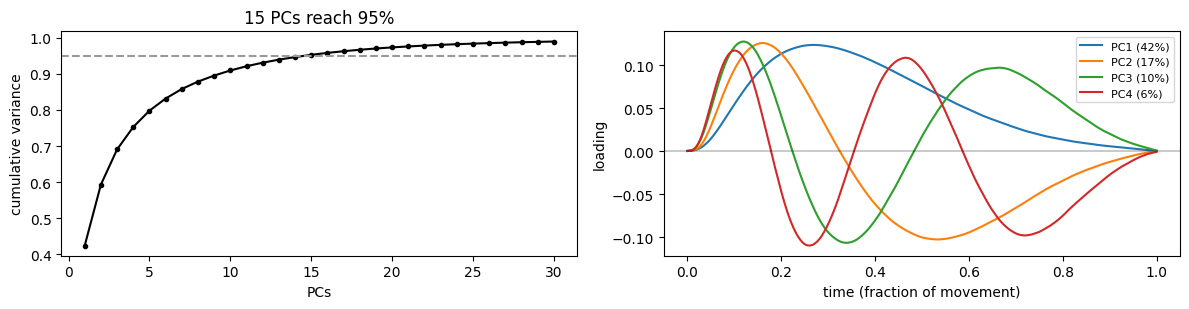

In [4]:
pca = PCA().fit(S)
n_pc = int(np.searchsorted(np.cumsum(pca.explained_variance_ratio_), VAR) + 1)
def features(S_, info_):
    F = np.column_stack([pca.transform(S_)[:, :n_pc], np.log10(info_.duration)])
    return (F - MU) / SD
F0 = np.column_stack([pca.transform(S)[:, :n_pc], np.log10(info.duration)])
MU, SD = F0.mean(0), F0.std(0)
F = (F0 - MU) / SD
def side_of(S_):
    pos = np.clip(S_, 0, None).sum(1); neg = np.clip(-S_, 0, None).sum(1)
    si = (pos - neg) / (pos + neg)                 # wheel coordinates: + / - travel balance
    return np.where(si > SPLIT, 2, np.where(si < -SPLIT, 0, 1))
if SPLIT_BY_SIDE:
    # absolute velocity: a single mixture builds nested, centred clusters of increasing speed that hold
    # both directions, so the wheel side is a hard split first: -side / balanced / +side, then a mixture each
    grp = side_of(S)
    GM = {g: GaussianMixture(KG[g], covariance_type='full', n_init=5, random_state=0).fit(F[grp == g]) for g in range(3)}
    OFF = np.r_[0, np.cumsum(KG)[:-1]]
    def predict(S_, info_):
        F_, g_ = features(S_, info_), side_of(S_)
        out = np.empty(len(S_), int)
        for g in range(3):
            if (g_ == g).any(): out[g_ == g] = GM[g].predict(F_[g_ == g]) + OFF[g]
        return out
else:
    gmm = GaussianMixture(K, covariance_type='full', n_init=5, random_state=0).fit(F)
    def predict(S_, info_):
        return gmm.predict(features(S_, info_))
lab = predict(S, info)
info['raw'] = lab
x = np.linspace(0, 1, pm.NT)

fig, axs = plt.subplots(1, 2, figsize=(12, 3.2))
axs[0].plot(np.arange(1, 31), np.cumsum(pca.explained_variance_ratio_[:30]), 'o-', c='k', ms=3)
axs[0].axhline(VAR, c='0.6', ls='--'); axs[0].set(xlabel='PCs', ylabel='cumulative variance', title=f'{n_pc} PCs reach {VAR:.0%}')
for i in range(4):
    axs[1].plot(x, pca.components_[i], label=f'PC{i + 1} ({pca.explained_variance_ratio_[i]:.0%})')
axs[1].axhline(0, c='k', lw=.3); axs[1].set(xlabel='time (fraction of movement)', ylabel='loading'); axs[1].legend(fontsize=8)
plt.tight_layout()
print(f'{n_pc} PCs kept')

### Describing the clusters: side, vigor, jitter

Per movement (from its signed, peak-normalised shape and its peak speed), then summarised per cluster:
- **side index** = (∫v⁺ − ∫v⁻) / (∫v⁺ + ∫v⁻), the balance of wheel travel in the two directions, then mapped to the stimulus side it reports. The mapping is measured, not assumed: on correct response-epoch movements, which wheel sign goes with right-side stimuli. +1 = all travel reports a right stimulus, −1 = left, 0 = balanced back-and-forth.
- **vigor** = median peak speed (rad/s).
- **jitter** = direction reversals per movement, counted where |v| > 10 % of the peak (so encoder noise around zero is ignored).

Heuristic labels: side = right / left if |median side index| > 0.5, else 'both'; vigor = low / mid / high by the cluster's median peak speed (< 1, 1–2.75, > 2.75 rad/s: fixed cuts, so the label means the same whatever the side); jitter = smooth (≤ 1 reversal), corrective (2–3), jittery (≥ 4).

In [5]:
pos = np.clip(S, 0, None).sum(1); neg = np.clip(-S, 0, None).sum(1)
si_wheel = (pos - neg) / (pos + neg)
def reversals(a, thr=.1):
    sg = np.sign(np.where(np.abs(a) > thr, a, 0))
    sg = sg[sg != 0]
    return int((np.diff(sg) != 0).sum())
info['reversals'] = [reversals(a, .1 * np.abs(a).max()) for a in S]
# which wheel sign reports a right stimulus? correct response-epoch movements
c = info[(info.epoch == 'response') & info.correct & (info.trial >= 0)]
p_pos_right = (si_wheel[c.index][c.stim_side == 'right'] > 0).mean()
p_pos_left = (si_wheel[c.index][c.stim_side == 'left'] > 0).mean()
SIGN_RIGHT = 1 if p_pos_right > p_pos_left else -1
print(f'P(+ wheel | right stim, correct) = {p_pos_right:.2f},  P(+ wheel | left stim, correct) = {p_pos_left:.2f}'
      f'  ->  + wheel reports {"right" if SIGN_RIGHT > 0 else "left"}')
info['side_index'] = si_wheel * SIGN_RIGHT          # + = reports right stimulus

desc = info.groupby('raw').agg(fraction=('raw', lambda c: len(c) / len(info)), side_index=('side_index', 'median'),
                               peak_rad_s=('peak', 'median'), reversals=('reversals', 'median'),
                               duration_s=('duration', 'median'),
                               response=('epoch', lambda e: (e == 'response').mean()),
                               post_feedback=('epoch', lambda e: (e == 'post-feedback').mean()))
desc['side'] = np.where(desc.side_index > .5, 'right', np.where(desc.side_index < -.5, 'left', 'both'))
desc['vigor'] = pd.cut(desc.peak_rad_s, [0, VIGOR_CUTS[0], VIGOR_CUTS[1], np.inf], labels=['low', 'mid', 'high']).astype(str)
desc['jitter'] = pd.cut(desc.reversals, [-1, 1, 3, 99], labels=['smooth', 'corrective', 'jittery']).astype(str)
# display order: left -> both -> right, and within a side from low to high vigor
side_rank = desc.side.map({'left': 0, 'both': 1, 'right': 2})
desc = desc.assign(_s=side_rank).sort_values(['_s', 'peak_rad_s']).drop(columns='_s')
desc['cls'] = np.arange(K)
REL = dict(zip(desc.index, desc.cls))
info['cls'] = info.raw.map(REL)
desc = desc.set_index('cls')
desc['label'] = desc.side + ' ' + desc.vigor + ' ' + desc.jitter
# colours: the paper's rule. gap > 0 -> hues[0]. Left = violet (310), right = amber (90), as the paw states.
COL = ps.state_palette(np.log(desc.peak_rad_s.values), gap=-desc.side_index.values, hues=(310, 90))
HATCH = {'smooth': '', 'corrective': '..', 'jittery': '////'}
print('NMI(cluster, mouse) =', round(nmi(info.mouse, info.cls), 3))
desc.round(2)

P(+ wheel | right stim, correct) = 0.82,  P(+ wheel | left stim, correct) = 0.18  ->  + wheel reports right
NMI(cluster, mouse) = 0.063


,fraction,side_index,peak_rad_s,reversals,duration_s,response,post_feedback,side,vigor,jitter,label
cls,,,,,,,,,,,
0,0.03,-1.00,0.24,0.0,0.10,0.15,0.67,left,low,smooth,left low smooth
1,0.03,-1.00,0.51,0.0,0.21,0.17,0.66,left,low,smooth,left low smooth
2,0.04,-0.92,1.21,1.0,0.38,0.31,0.49,left,mid,smooth,left mid smooth
3,0.05,-0.87,2.29,1.0,0.58,0.43,0.31,left,mid,smooth,left mid smooth
4,0.06,-0.76,2.95,2.0,1.00,0.57,0.20,left,high,corrective,left high corrective
5,0.02,-0.95,3.09,1.0,0.81,0.76,0.10,left,high,smooth,left high smooth
6,0.04,-0.69,4.25,4.0,1.74,0.63,0.17,left,high,jittery,left high jittery
7,0.03,-0.00,0.35,1.0,0.15,0.21,0.67,both,low,smooth,both low smooth
8,0.05,-0.01,0.65,2.0,0.37,0.22,0.58,both,low,corrective,both low corrective


#### Is the clustering sensitive to amplitude?

clusters explain 75% of the variance in log peak speed (through shape and duration, not amplitude itself)


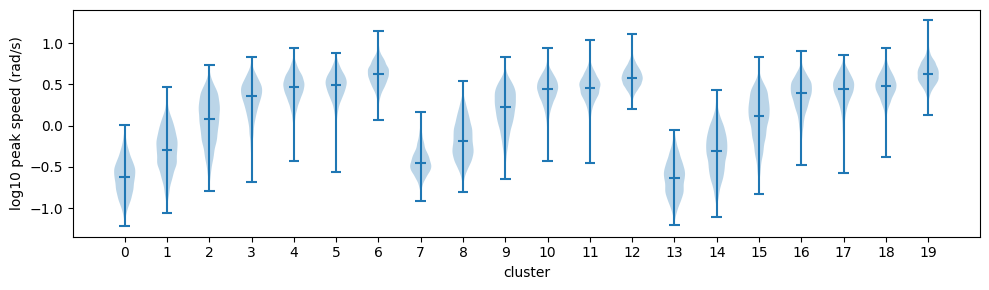

In [6]:
# shapes are peak-normalised, so vigor is not a feature; how much of the peak-speed variance do clusters capture anyway?
lp = np.log10(info.peak)
eta2 = 1 - info.assign(lp=lp).groupby('cls').lp.transform(lambda z: z - z.mean()).pow(2).sum() / ((lp - lp.mean()) ** 2).sum()
print(f'clusters explain {eta2:.0%} of the variance in log peak speed (through shape and duration, not amplitude itself)')
fig, ax = plt.subplots(figsize=(10, 3))
ax.violinplot([lp[info.cls == c] for c in range(K)], positions=range(K), showmedians=True)
ax.set(xticks=range(K), xlabel='cluster', ylabel='log10 peak speed (rad/s)'); plt.tight_layout()

#### Legend: the colour code

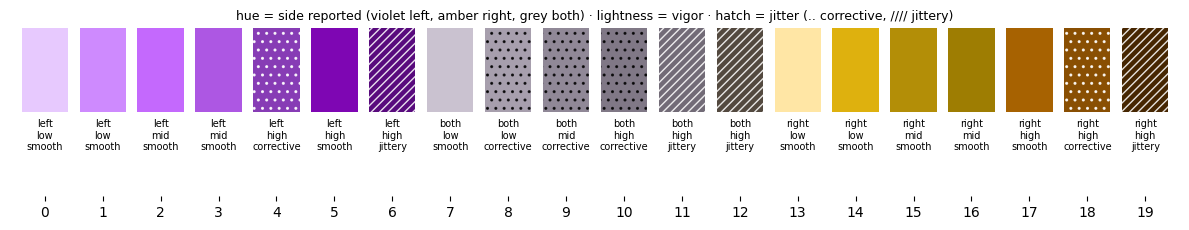

In [7]:
fig, ax = plt.subplots(figsize=(12, 2.4))
for c in range(K):
    ax.bar(c, 1, color=COL[c], hatch=HATCH[desc.jitter[c]], edgecolor=ps.hatch_ink(COL[c]), lw=0)
    ax.text(c, -.08, desc.label[c].replace(' ', '\n'), ha='center', va='top', fontsize=7)
ax.set(xticks=range(K), xlim=(-.6, K - .4), ylim=(-1.0, 1), yticks=[])
ax.set_title('hue = side reported (violet left, amber right, grey both) · lightness = vigor · hatch = jitter (.. corrective, //// jittery)', fontsize=9)
for sp in ax.spines.values(): sp.set_visible(False)
plt.tight_layout()

### Save the fitted model (no labels)

The PCA, standardisation, mixture(s), display order, labels and colours, so other notebooks can label any session with `proficient_movements.predict` / `session_labels`.

In [8]:
import pickle
MODEL = dict(variant='normalised' if NORMALISE else 'absolute', normalise=NORMALISE, pca=pca, n_pc=n_pc, MU=MU, SD=SD,
             split_by_side=SPLIT_BY_SIDE, SPLIT=SPLIT, REL=REL, desc=desc, COL=COL, HATCH=HATCH, K=K)
if SPLIT_BY_SIDE:
    MODEL.update(GM=GM, OFF=OFF)
else:
    MODEL['gmm'] = gmm
with open(pm.model_path(MODEL['variant']), 'wb') as f:
    pickle.dump(MODEL, f)
print('saved', pm.model_path(MODEL['variant']))

saved /home/ines/repositories/representation_learning_variability/paper-individuality/data/wheel_movements_proficient/model_absolute.pkl


#### 60 vs 200 Hz: do the same movements get the same cluster?

In [9]:
S60, S200, both = CHK
l60 = predict(S60, both.rename(columns={'duration_60': 'duration'}))
l200 = predict(S200, both.rename(columns={'duration_200': 'duration'}))
print(f'{len(both)} movements: same cluster {np.mean(l60 == l200):.0%}, ARI {ari(l60, l200):.2f}')

1431 movements: same cluster 93%, ARI 0.87


#### Each cluster: 60 random members (thin) and median (thick); x = fraction of the movement, + = one wheel direction

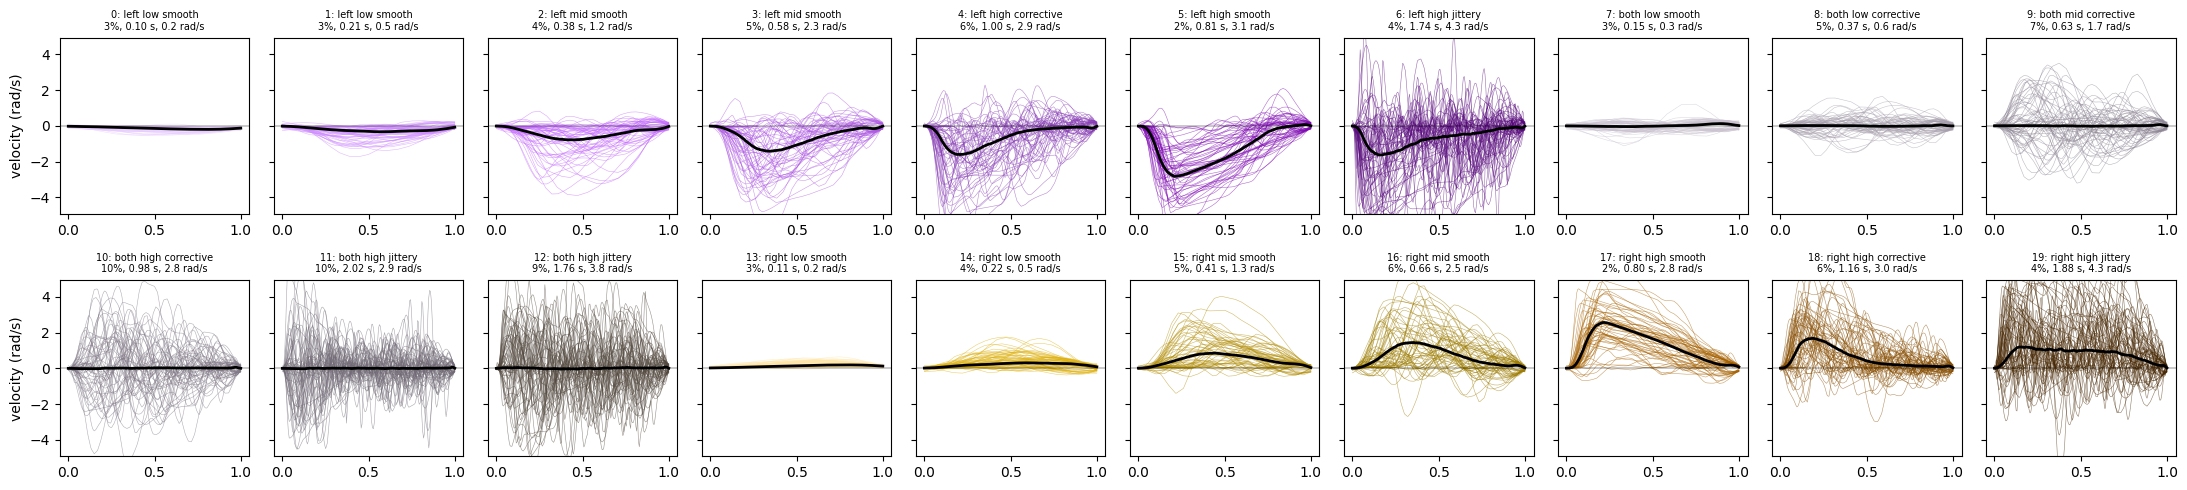

In [10]:
YL = np.percentile(np.abs(S), 99.5)
fig, axs = plt.subplots(2, K // 2, figsize=(2.2 * K / 2, 5), sharey=True)
for c, ax in enumerate(axs.flat):
    a = S[info.cls == c]
    ax.plot(x, a[rng.choice(len(a), min(60, len(a)), replace=False)].T, c=COL[c], lw=.4, alpha=.6)
    ax.plot(x, np.median(a, 0), c='k', lw=2); ax.axhline(0, c='k', lw=.3)
    ax.set_ylim(-1.05, 1.05) if NORMALISE else ax.set_ylim(-YL, YL)
    ax.set_title(f'{c}: {desc.label[c]}\n{len(a) / len(S):.0%}, {desc.duration_s[c]:.2f} s, {desc.peak_rad_s[c]:.1f} rad/s', fontsize=7)
for ax in axs[:, 0]: ax.set_ylabel('velocity / peak' if NORMALISE else 'velocity (rad/s)')
plt.tight_layout()

#### Each cluster in real time: random members from any mouse, rad/s, x = seconds from onset

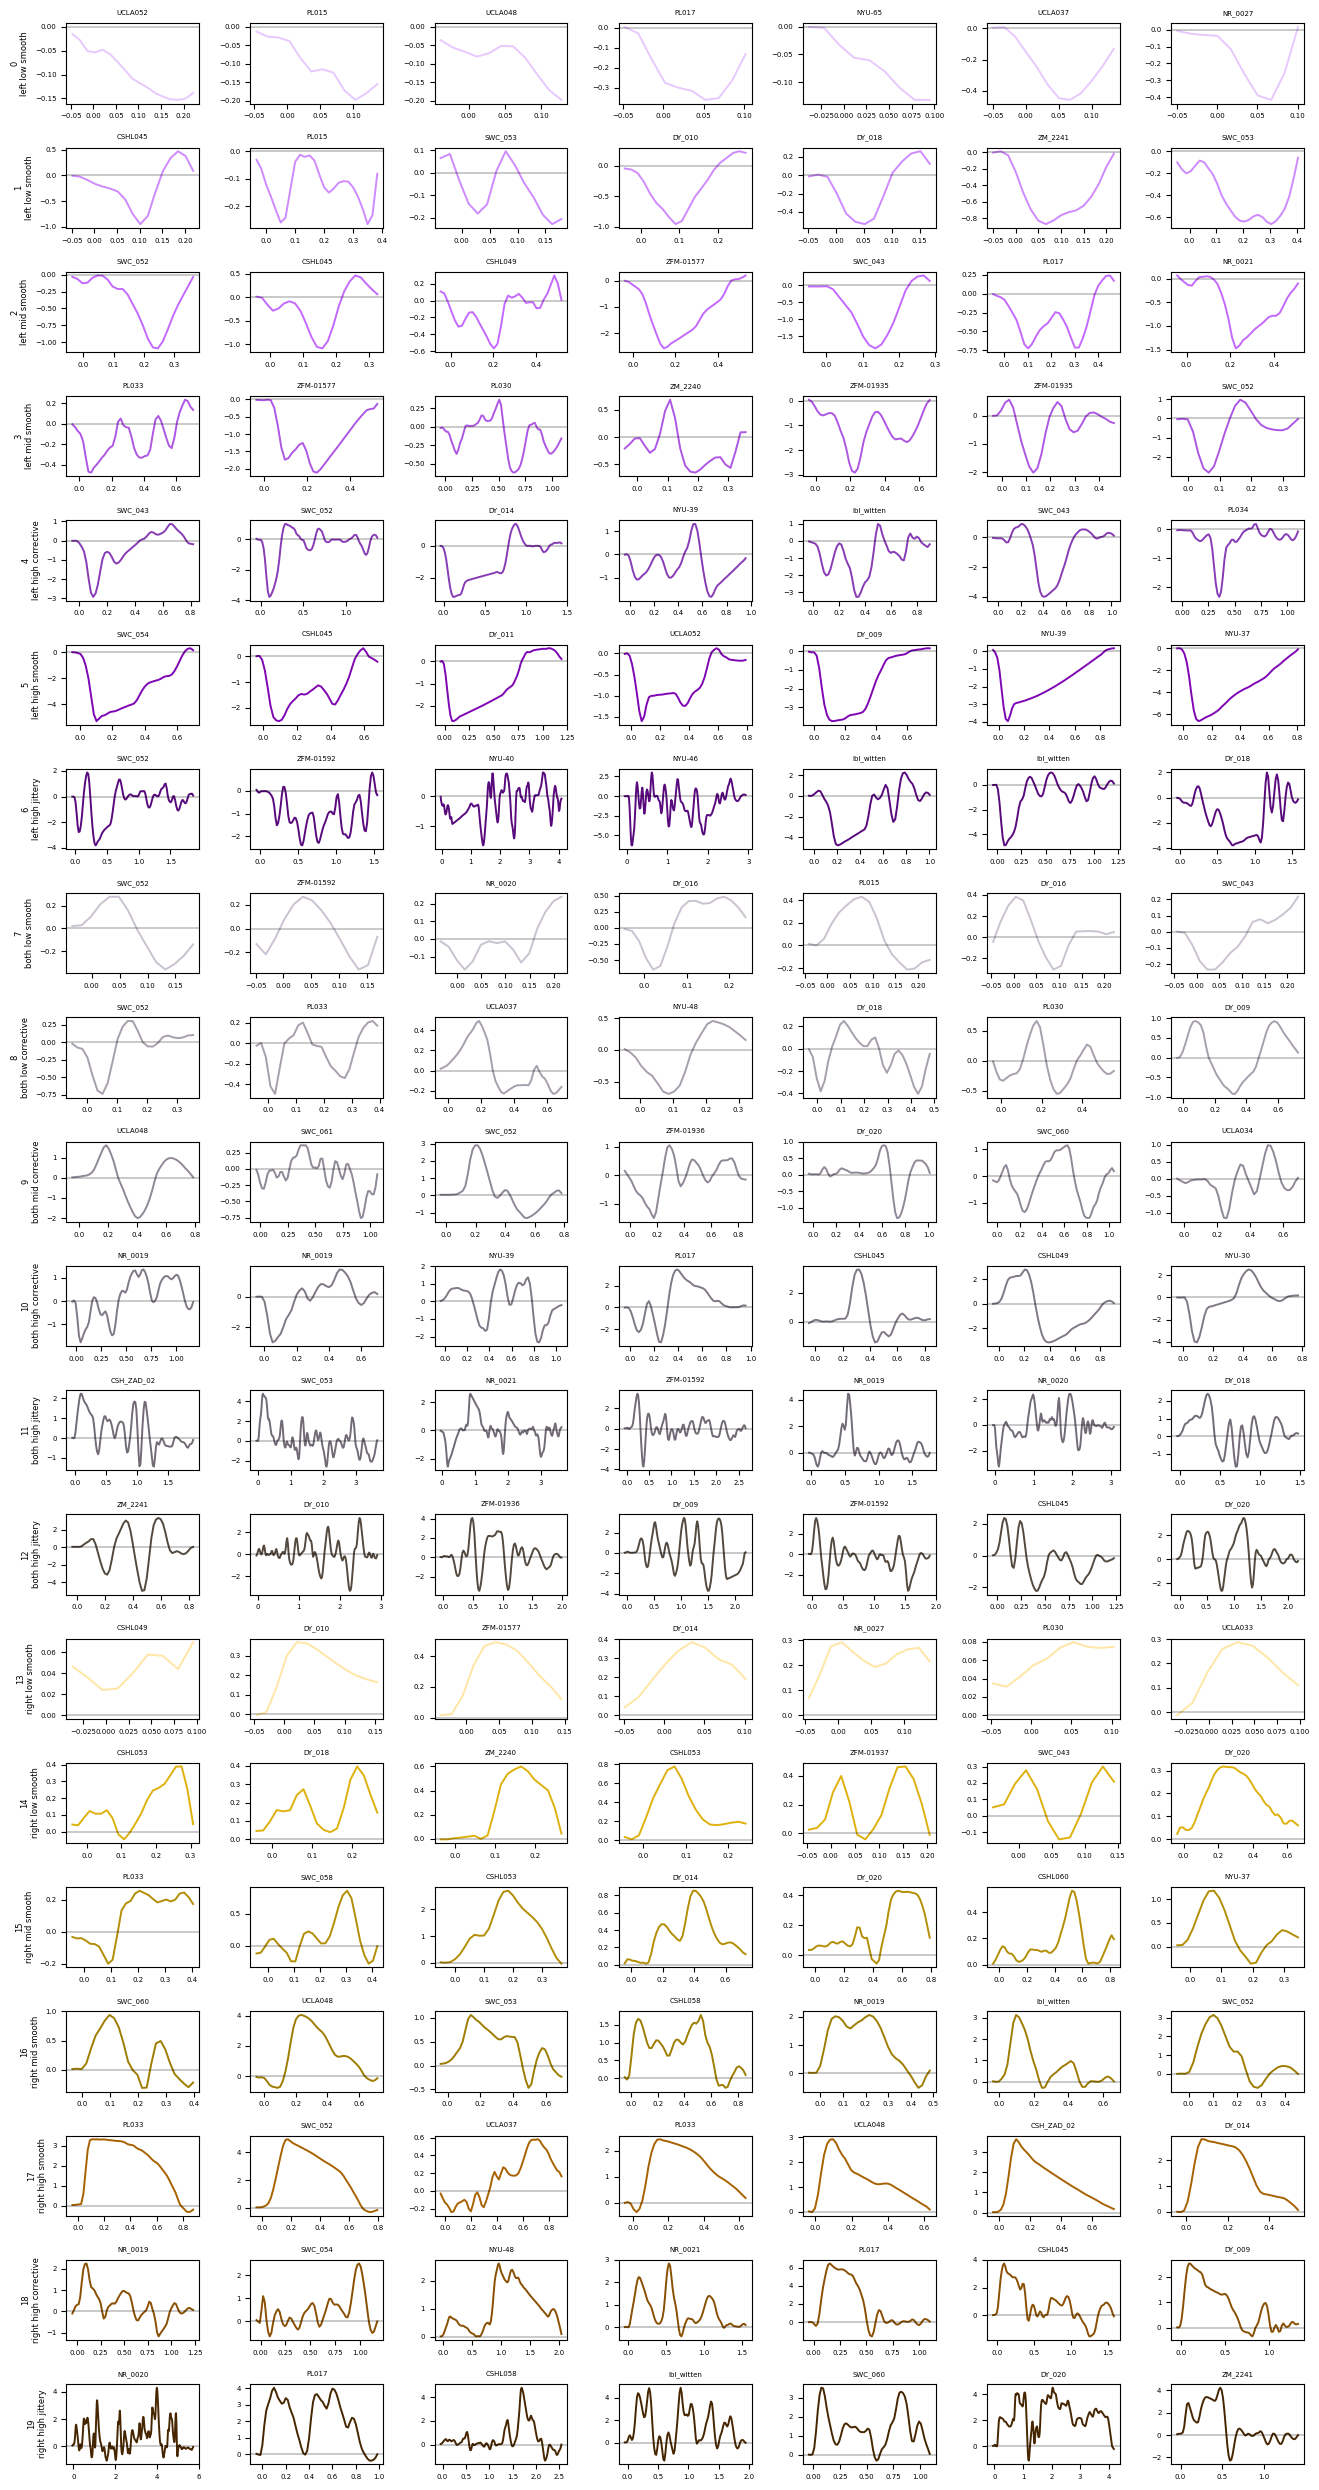

In [11]:
N_EX = 7
DMC = {}
def vel(e):
    if e not in DMC:
        m = coh.set_index('eid').mouse[e]
        DMC[e] = pm.load_session(e, m)[:2]
    return DMC[e]
fig, axs = plt.subplots(K, N_EX, figsize=(1.9 * N_EX, 1.25 * K), squeeze=False)
for c in range(K):
    for j, i in enumerate(rng.choice(info.index[info.cls == c], N_EX, replace=False)):
        q = info.loc[i]; t, v = vel(q.eid); ax = axs[c, j]
        i0, i1 = np.searchsorted(t, [q.onset - pm.PAD_S, q.offset + pm.PAD_S])
        ax.plot(t[i0:i1] - q.onset, v[i0:i1], c=COL[c], lw=1.4); ax.axhline(0, c='k', lw=.3); ax.tick_params(labelsize=5)
        ax.set_title(q.mouse[:10], fontsize=5)
    axs[c, 0].set_ylabel(f'{c}\n{desc.label[c]}', fontsize=6)
plt.tight_layout()

### Shared across mice? Cluster use per mouse (rows = mice, sorted by lab name)

clusters used by every mouse (> 0.5 % of its movements): 11 of 20


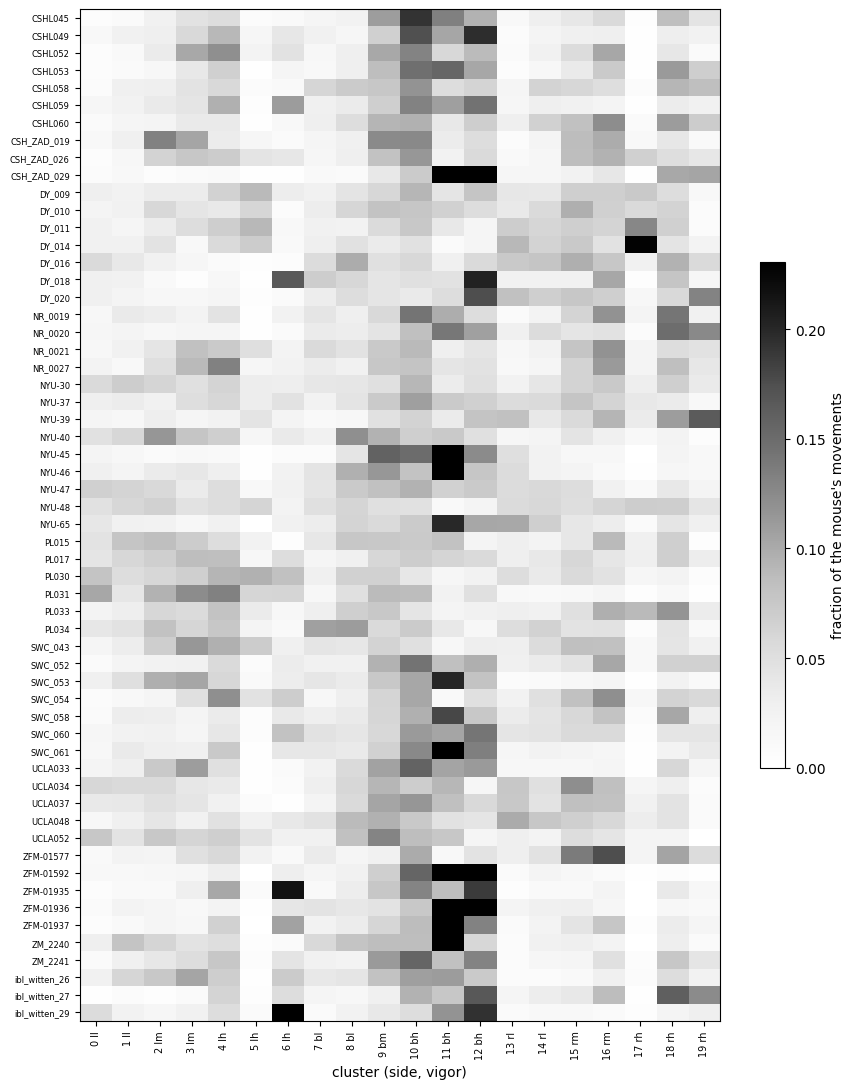

In [12]:
u = info.groupby('mouse').cls.value_counts(normalize=True).unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(9, 11))
im = ax.imshow(u.values, aspect='auto', cmap='Greys', vmax=np.percentile(u.values, 99))
ax.set_yticks(range(len(u)), u.index, fontsize=6); ax.set_xticks(range(K), [f'{c} {desc.side[c][0]}{desc.vigor[c][0]}' for c in range(K)], fontsize=7, rotation=90); ax.set_xlabel('cluster (side, vigor)')
plt.colorbar(im, ax=ax, label='fraction of the mouse\'s movements', shrink=.5); plt.tight_layout()
print('clusters used by every mouse (> 0.5 % of its movements):', int(((u > .005).all(0)).sum()), 'of', K)

#### The clusters in time (display only, nothing saved): 25 s from 4 sessions of different mice

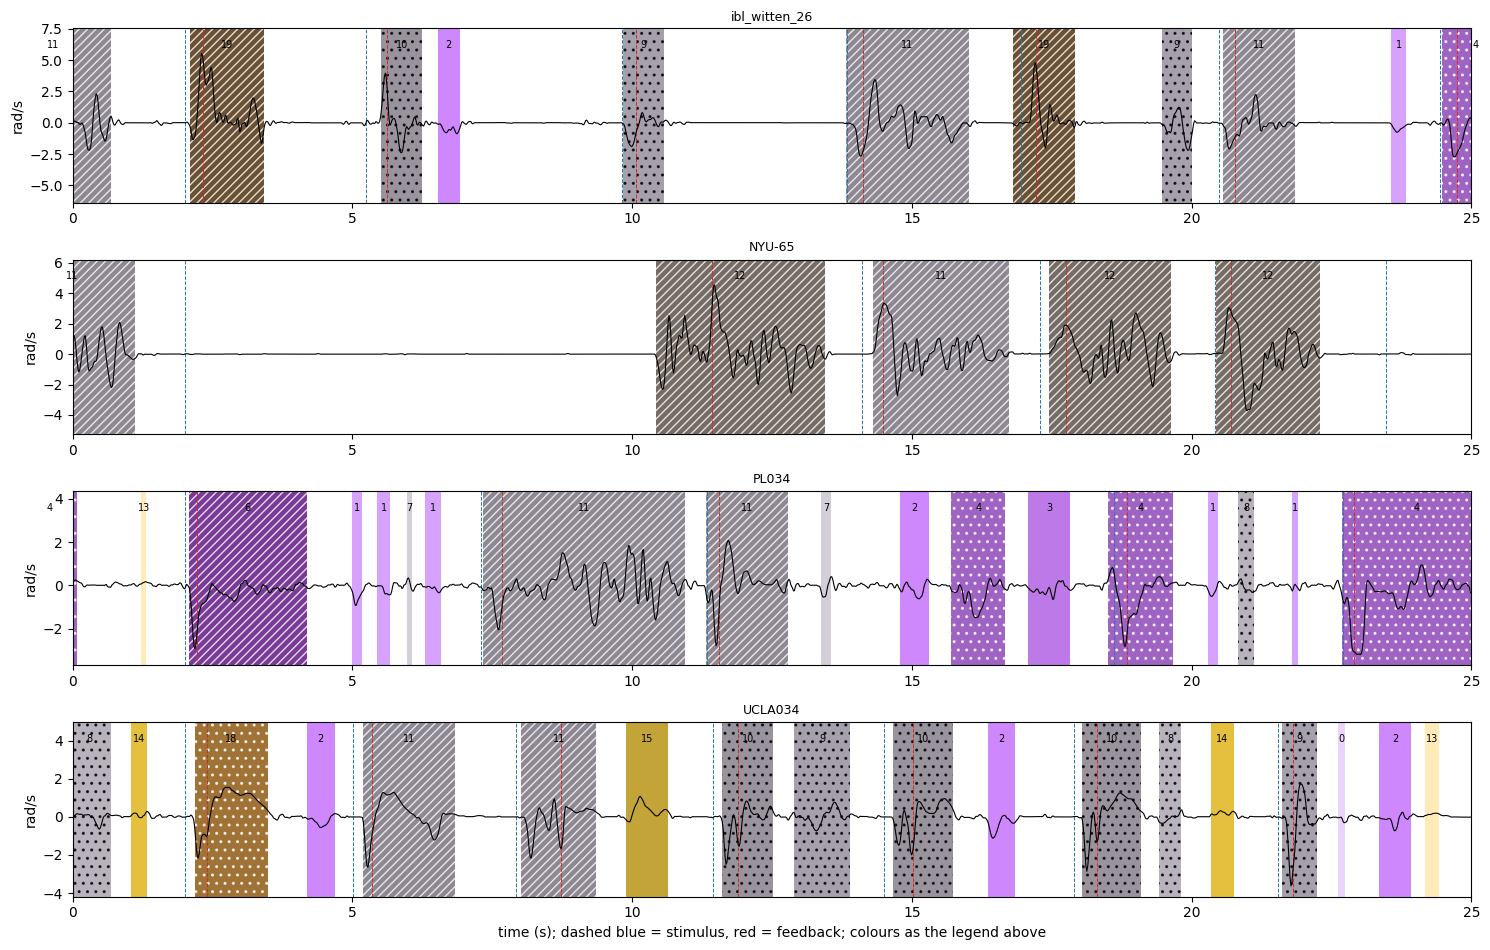

In [13]:
def timeline(e, ax, frac=.4, win=25):
    m = coh.set_index('eid').mouse[e]
    t, v, iv, tr = pm.load_session(e, m)
    Se, ie = ALL_S[e], ALL_I[e]
    le = pd.Series(predict(Se, ie)).map(REL).values
    stim = pr.stim_times(tr)
    t0 = stim.iloc[int(frac * len(tr))] - 2
    sel = (t > t0) & (t < t0 + win)
    ax.plot(t[sel] - t0, v[sel], c='k', lw=.8, zorder=3)
    top = np.nanmax(np.abs(v[sel])) * 1.05
    for (_, q), c in zip(ie.iterrows(), le):
        if q.offset > t0 and q.onset < t0 + win:
            ax.axvspan(q.onset - t0, q.offset - t0, facecolor=COL[c], hatch=HATCH[desc.jitter[c]], edgecolor=ps.hatch_ink(COL[c]), alpha=.8, lw=0)
            ax.text((q.onset + q.offset) / 2 - t0, top, str(c), ha='center', va='bottom', fontsize=7)
    for ev, col in [(stim.values, 'tab:blue'), (tr.feedback_times.values, 'tab:red')]:
        for x_ in ev:
            if 0 < x_ - t0 < win: ax.axvline(x_ - t0, c=col, ls='--', lw=.7)
    ax.set(xlim=(0, win), ylim=(-top * 1.1, top * 1.3), ylabel='rad/s'); ax.set_title(m, fontsize=9)

show = coh.groupby('mouse').eid.first().sample(4, random_state=2).values
fig, axs = plt.subplots(len(show), 1, figsize=(15, 2.4 * len(show)))
for ax, e in zip(axs, show):
    timeline(e, ax)
axs[-1].set_xlabel('time (s); dashed blue = stimulus, red = feedback; colours as the legend above')
plt.tight_layout()

### Mouse ICC of cluster occupancy

Every movement of every cohort session is labelled **in memory** (nothing saved). Per session: the fraction of its movements in each cluster, overall and within each trial epoch (by movement onset). ICC(1) per cluster: one-way random effects with mice as groups and sessions as repeats (unequal group sizes handled with the usual n0). ICC = share of the session-to-session variance in occupancy that is between mice. The table is written to `icc_<variant>.csv` in the movement cache, so the variants can be compared.

ONE mouse ICC per epoch for the whole occupancy profile (Hellinger = on sqrt(occupancy), less dominated by the big clusters):


,icc_occupancy,icc_hellinger
epoch,,
all,0.640,0.662
pre-stim,0.553,0.553
response,0.631,0.616
post-feedback,0.550,0.582


/tmp/ipykernel_216643/1665315986.py:43: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  summ_icc = ICC.groupby('epoch').apply(lambda d: pd.Series({'median ICC': d.icc.median(),


,median ICC,occupancy-weighted ICC,clusters ICC > 0.3
epoch,,,
all,0.597,0.600,20.0
pre-stim,0.525,0.536,20.0
response,0.493,0.570,19.0
post-feedback,0.552,0.542,20.0


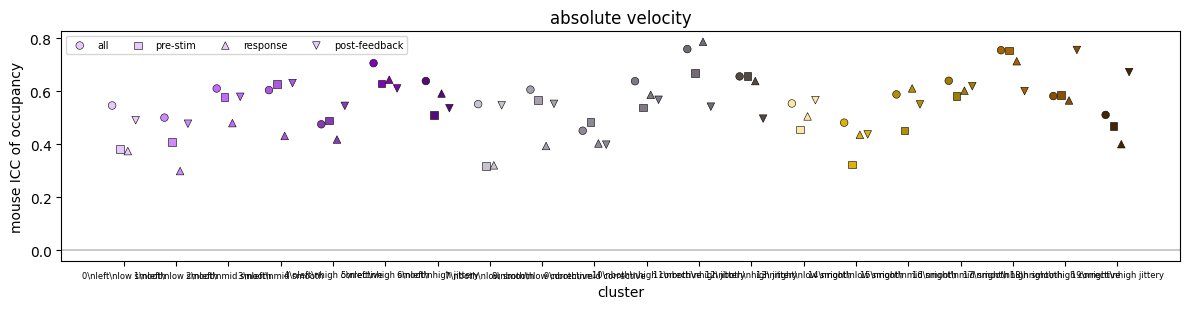

In [14]:
def icc1(df, value, group='mouse'):
    g = df.groupby(group)[value]
    n_i, k = g.size(), g.ngroups
    N = n_i.sum()
    grand = df[value].mean()
    msb = (n_i * (g.mean() - grand) ** 2).sum() / (k - 1)
    msw = ((df[value] - g.transform('mean')) ** 2).sum() / (N - k)
    n0 = (N - (n_i ** 2).sum() / N) / (k - 1)
    return (msb - msw) / (msb + (n0 - 1) * msw)

lab_all = pd.concat([ALL_I[e].assign(cls=pd.Series(predict(ALL_S[e], ALL_I[e])).map(REL).values) for e in coh.eid],
                    ignore_index=True)
rows = []
for epoch in ['all'] + pr.EPOCHS:
    d = lab_all if epoch == 'all' else lab_all[lab_all.epoch == epoch]
    occ = d.groupby(['mouse', 'eid']).cls.value_counts(normalize=True).unstack(fill_value=0).reindex(columns=range(K), fill_value=0)
    occ = occ.reset_index()
    for c in range(K):
        rows.append(dict(epoch=epoch, cls=c, label=desc.label[c], mean_occupancy=occ[c].mean(), icc=icc1(occ, c)))
ICC = pd.DataFrame(rows)
def icc_pooled(occ, transform=None):
    """ONE ICC for the whole occupancy profile: the ANOVA variance components summed over clusters
    (between-mouse share of the total session-to-session variance of the occupancy vector)."""
    X = occ[list(range(K))].values
    if transform == 'hellinger': X = np.sqrt(X)
    m = occ['mouse'].values; mice = np.unique(m); N, k = len(X), len(mice)
    n_i = np.array([(m == u).sum() for u in mice]); means = np.array([X[m == u].mean(0) for u in mice])
    msb = (n_i[:, None] * (means - X.mean(0)) ** 2).sum() / (k - 1)
    msw = sum(((X[m == u] - means[j]) ** 2).sum() for j, u in enumerate(mice)) / (N - k)
    n0 = (N - (n_i ** 2).sum() / N) / (k - 1)
    return (msb - msw) / (msb + (n0 - 1) * msw)
POOL = []
for epoch in ['all'] + pr.EPOCHS:
    d = lab_all if epoch == 'all' else lab_all[lab_all.epoch == epoch]
    occ = d.groupby(['mouse', 'eid']).cls.value_counts(normalize=True).unstack(fill_value=0).reindex(columns=range(K), fill_value=0).reset_index()
    POOL.append(dict(epoch=epoch, icc_occupancy=icc_pooled(occ), icc_hellinger=icc_pooled(occ, 'hellinger')))
POOL = pd.DataFrame(POOL).set_index('epoch')
POOL.assign(variant='normalised' if NORMALISE else 'absolute').to_csv(pm.CACHE / f"icc_pooled_{'normalised' if NORMALISE else 'absolute'}.csv")
print('ONE mouse ICC per epoch for the whole occupancy profile (Hellinger = on sqrt(occupancy), less dominated by the big clusters):')
display(POOL.round(3))
variant = 'normalised' if NORMALISE else 'absolute'
ICC.assign(variant=variant).to_csv(pm.CACHE / f'icc_{variant}.csv', index=False)
summ_icc = ICC.groupby('epoch').apply(lambda d: pd.Series({'median ICC': d.icc.median(),
                                                           'occupancy-weighted ICC': np.average(d.icc, weights=d.mean_occupancy),
                                                           'clusters ICC > 0.3': int((d.icc > .3).sum())})).reindex(['all'] + pr.EPOCHS)
display(summ_icc.round(3))
fig, ax = plt.subplots(figsize=(12, 3.2))
for j, (ep, m) in enumerate(zip(['all'] + pr.EPOCHS, ['o', 's', '^', 'v'])):
    q = ICC[ICC.epoch == ep]
    ax.scatter(q.cls + (j - 1.5) * .15, q.icc, c=[COL[c] for c in q.cls], marker=m, edgecolors='k', lw=.4, s=30, label=ep)
ax.axhline(0, c='k', lw=.3); ax.set(xticks=range(K), xlabel='cluster', ylabel='mouse ICC of occupancy', title=f'{variant} velocity')
ax.set_xticklabels([f'{c}\\n{desc.label[c]}'.replace(' ', '\\n', 1) for c in range(K)], fontsize=6)
ax.legend(fontsize=7, ncol=4); plt.tight_layout()